## **Exam Project Notebook (Main) - Foundations of Deep Learning**  
### *Classification of Aquatic Animals Images Using Convolutional Neural Networks*  

---

**Authors:** *Daniela Lorriz Bautista (ID 900074), Matteo Fumagalli (ID 894468)*  
**University:** *University of Milano-Bicocca*  
**Degree Program:** *Master’s Degree in Data Science*   
**Academic Year:** *2025/2026*

---

### **Notebook Description**
This notebook implements the deep learning pipeline for designing, training, and evaluating different Convolutional Neural Network (CNN) architectures in order to solve a classification task. The models are trained on a custom 10-class subsample of aquatic animals extracted from Google's Quick, Draw! dataset.  

All steps are fully reproducible from the files provided in this repository.

---

## **0. Environment setup**

In [ ]:
# Install external libraries
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 13.4 MB/s eta 0:00:00


In [ ]:
# Import libraries
import cv2
import math
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import os
import random
from shutil import copyfile
import zipfile
import math

import tensorflow as tf
from tensorflow import keras
import keras_tuner as kt
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.auto import tqdm

# Set seed for reproducibility
SEED = 3
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

# Define colab settings
from IPython.display import Javascript
def resize_colab_cell():
    display(Javascript(
        'google.colab.output.setIframeHeight(0, true, {maxHeight: 500})'))
get_ipython().events.register('pre_run_cell', resize_colab_cell)

# Define paths for dataset and models
DATASET_DIR = '/content/drive/MyDrive/foundations-of-deep-learning/data/quickdraw_dataset.zip'
MODELS_DIR = '/content/drive/MyDrive/foundations-of-deep-learning/models'
VISUALIZATIONS_DIR = '/content/drive/MyDrive/foundations-of-deep-learning/visualizations'

print('-> Environment configured correctly')

-> Environment configured correctly


---

## **1. Drive Connection and Data Loading**

In [ ]:
# Connect to drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

<IPython.core.display.Javascript object>

Mounted at /content/drive


In [ ]:
# Copy zip from Drive to Colab local storage
copyfile(DATASET_DIR,
         '/content/quickdraw_dataset.zip')

# Extract dataset
with zipfile.ZipFile('/content/quickdraw_dataset.zip', 'r') as zip_file:
    zip_file.extractall('/content/dataset')

print('-> Dataset extracted')

<IPython.core.display.Javascript object>

-> Dataset extracted


---

## **2. Data Visualization**

In [ ]:
def get_image_paths(dataset_directory, split='train', class_name=None):
    '''Extract all paths of the images of a specific split'''

    # Obtain the path of the split
    split_directory = os.path.join(dataset_directory, split)

    if not os.path.exists(split_directory):
        raise ValueError(f'-> Split directory not found: {split_directory}')

    image_paths_per_class = {}
    if class_name is not None:
        # Obtain the paths of the files of the class within the split
        class_directory = os.path.join(split_directory, class_name)
        if not os.path.exists(class_directory):
            raise ValueError('-> Class directory not found: '
                             f'{class_directory}')

        files = [
            os.path.join(class_directory, file)
            for file in os.listdir(class_directory) if file.endswith('.png')]
        if files:
            image_paths_per_class[class_name] = files
    else:
        # Obtain the paths of the files of all classes within the split
        for class_name in os.listdir(split_directory):
            class_directory = os.path.join(split_directory, class_name)
            if os.path.isdir(class_directory):
                files = [
                    os.path.join(class_directory, file)
                    for file in os.listdir(class_directory)
                    if file.endswith('.png')]
                if files:
                    image_paths_per_class[class_name] = files

    if not image_paths_per_class:
        raise ValueError('\n-> No images found')

    return image_paths_per_class


def show_random_image(dataset_directory, split='train', class_name=None):
    '''Show a random image of a specific split'''
    images_paths_per_class = get_image_paths(
        dataset_directory, split, class_name)

    image_paths = []
    for paths in images_paths_per_class.values():
        image_paths.extend(paths)

    # Extract and display a random image from the set of all paths
    image_path = random.choice(image_paths)
    selected_class = os.path.basename(os.path.dirname(image_path))

    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    plt.figure(figsize=(4, 4))
    plt.imshow(image, cmap='gray')
    plt.title(f'Class: {selected_class} - Split: {split}')
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    print(f'\nImage path: {image_path}')


def show_grid_of_images(dataset_directory, split='train'):
    '''Show a grid with a random image per each class'''
    images_paths_per_class = get_image_paths(dataset_directory, split)
    classes = sorted(list(images_paths_per_class.keys()))
    num_cols = 5
    num_rows = math.ceil(len(classes) / num_cols)

    # Extract and display a random image from each class
    fig, axes = plt.subplots(
        num_rows, num_cols, squeeze=False)
    axes = axes.flatten()

    for i, class_name in enumerate(classes):
        ax = axes[i]
        image_path = random.choice(images_paths_per_class[class_name])
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        ax.imshow(image, cmap='gray')
        ax.set_title(f'{class_name.capitalize()}', fontsize=10, pad=10)
        ax.axis('off')

    for j in range(i+1, len(axes)):
        axes[j].axis('off')
    plt.suptitle(f'Split: {split.upper()}',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(VISUALIZATIONS_DIR, f'images_grid_{split}.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

<IPython.core.display.Javascript object>

In [ ]:
def plot_distribution(dataset_directory):
  '''Display the number of images within each class for each split'''
  splits = ['train', 'validation', 'test']
  data = []

  # Count the number of images in each split
  for split in splits:
      split_path = os.path.join(dataset_directory, split)

      if not os.path.exists(split_path):
          continue

      for class_name in os.listdir(split_path):
          class_path = os.path.join(split_path, class_name)
          if os.path.isdir(class_path):
              num_images = len([
                  file for file in os.listdir(class_path)
                  if file.endswith('.png')])
              data.append({
                  'Split': split.capitalize(),
                  'Class': class_name.capitalize(),
                  'Number of Images': num_images})
  df = pd.DataFrame(data)

  # Plot the distribution of images per class and set
  plt.figure(figsize=(10, 4))
  sns.barplot(data=df, x='Class', y='Number of Images',
              hue='Split', palette='viridis')
  plt.title('Distribution of images by Class and Set',
            fontsize=14, fontweight='bold', pad=15)
  plt.xlabel('Class', fontsize=12)
  plt.ylabel('Number of Images', fontsize=12)
  plt.legend(title='Split Set')
  plt.tight_layout()
  plt.show()

  return df


def plot_overall_distribution(dataset_directory, df):
  '''Plot the overall distribution of images'''
  df_overall = df.groupby('Split')['Number of Images'].sum()
  labels = [f'{split.capitalize()}\n({int(count):,} images)'
            for split, count in df_overall.items()]

  plt.figure(figsize=(4, 4))
  patches, texts, autotexts = plt.pie(
      df_overall.values,
      labels=labels,
      autopct='%1.0f%%',
      startangle=90,
      colors=sns.color_palette('viridis', n_colors=len(df_overall)),
      wedgeprops={'edgecolor': 'black', 'linewidth': 1},
      textprops={'fontsize': 8},
      labeldistance=1.25)

  plt.title('Overall Distribution of Images',
            fontsize=10, fontweight='bold', pad=15)
  plt.tight_layout()
  plt.savefig(os.path.join(VISUALIZATIONS_DIR, 'overall_distribution.png'),
              dpi=300, bbox_inches='tight')
  plt.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

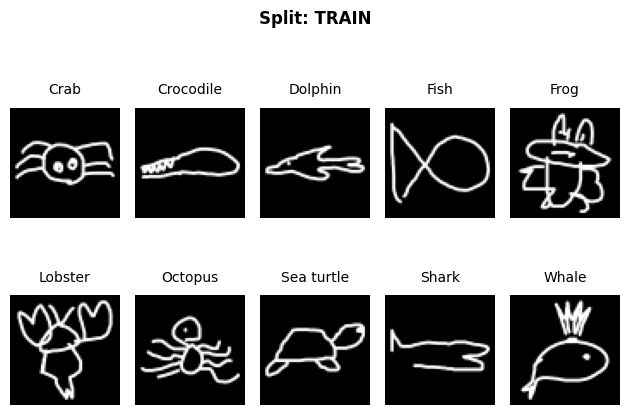

In [ ]:
# Show a grid of random images for the train set
show_grid_of_images('/content/dataset', split='train')

<IPython.core.display.Javascript object>

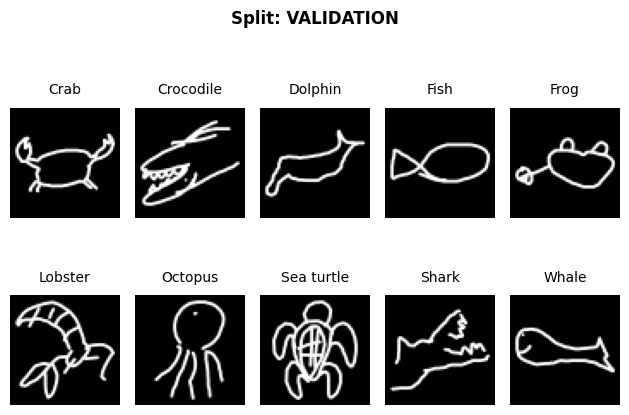

In [ ]:
# Show a grid of random images for the validation set
show_grid_of_images('/content/dataset', split='validation')

<IPython.core.display.Javascript object>

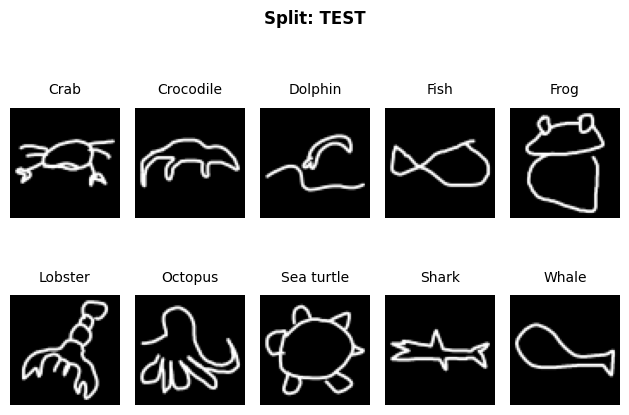

In [ ]:
# Show a grid of random images for the test set
show_grid_of_images('/content/dataset', split='test')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

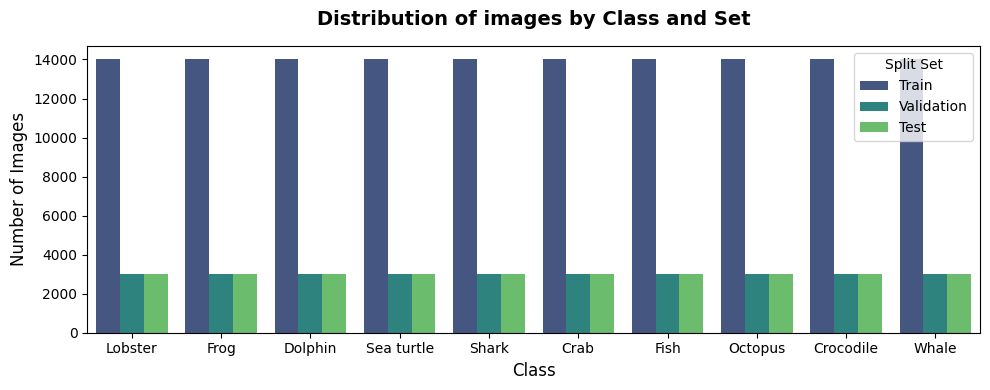

In [ ]:
# Display the number of images within each class for each split
df_distribution = plot_distribution('/content/dataset')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

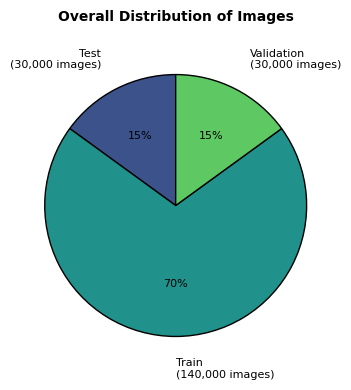

In [ ]:
# Display the overall distribution of images
plot_overall_distribution('/content/dataset', df_distribution)

---

## **3. Data Preprocessing**

In [ ]:
# Define global costants
IMG_SIZE=(64, 64)
BATCH_SIZE=64
NUM_CLASSES=10

# Load train set
print('-> Loading Training Set:')
train_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/dataset/train',
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', color_mode='grayscale',
    shuffle=True, seed=SEED)

# Load validation set
print('-> Loading Validation Set:')
validation_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/dataset/validation',
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', color_mode='grayscale',
    shuffle=False, seed=SEED)

# Load test set
print('-> Loading Test Set:')
test_ds = tf.keras.utils.image_dataset_from_directory(
    '/content/dataset/test',
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', color_mode='grayscale',
    shuffle=False, seed=SEED)

# Display the list of classes
class_names = train_ds.class_names
print(f'\nList of classes:')
for i, class_name in enumerate(class_names):
    print(f'{i+1}. {class_name.capitalize()}')

<IPython.core.display.Javascript object>

-> Loading Training Set:
Found 140000 files belonging to 10 classes.
-> Loading Validation Set:
Found 30000 files belonging to 10 classes.
-> Loading Test Set:
Found 30000 files belonging to 10 classes.

List of classes:
1. Crab
2. Crocodile
3. Dolphin
4. Fish
5. Frog
6. Lobster
7. Octopus
8. Sea turtle
9. Shark
10. Whale


In [ ]:
# Load RGB datasets for Transfer Learning as MobileNetV2 requires 3 channels
print('-> Loading RGB datasets for Transfer Learning:')
train_ds_rgb = tf.keras.utils.image_dataset_from_directory(
    '/content/dataset/train',
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', color_mode='rgb',
    shuffle=True, seed=SEED)

validation_ds_rgb = tf.keras.utils.image_dataset_from_directory(
    '/content/dataset/validation',
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', color_mode='rgb',
    shuffle=False, seed=SEED)

test_ds_rgb = tf.keras.utils.image_dataset_from_directory(
    '/content/dataset/test',
    image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', color_mode='rgb',
    shuffle=False, seed=SEED)

print('\n-> RGB datasets ready')

<IPython.core.display.Javascript object>

-> Loading RGB datasets for Transfer Learning:
Found 140000 files belonging to 10 classes.
Found 30000 files belonging to 10 classes.
Found 30000 files belonging to 10 classes.

-> RGB datasets ready


---

## **4. CNN Architectures**

---

### **4.1 Model Design**



**Baseline CNN**

This minimal 2-block CNN architecture serves as a baseline reference model, establishing the lower performance bound against which all subsequent architectures are evaluated.
- The `2 convolutional blocks` are sufficient to capture the fundamental stroke patterns (edges, shapes) without introducing architectural complexities. This ensures that performance gains in subsequent models can be attributed more clearly to added design choices.
- Therefore, the number of `filters increases from 32 to 64` across the two blocks, doubling at each stage to enable the network to encode progressively richer and more abstract features.
- `No intermediate Dense layers` are included: the output of the GlobalAveragePooling2D layer is passed directly to the final classifier, keeping the architecture compact and computationally lightweight.
- The `GlobalAveragePooling2D layer` aggregates each feature map spatially, a design choice suited to the spatially distributed stroke patterns, characteristic of Quick, Draw! sketches.

In [ ]:
# Baseline Model
def build_baseline_model(input_shape=(64, 64, 1), num_classes=10):
    '''Define a simple 2-block CNN baseline'''

    inputs = keras.Input(shape=input_shape)

    x = keras.layers.Rescaling(1./255)(inputs)

    # Block 1: detect low-level features (strokes, edges)
    x = keras.layers.Conv2D(32, 3, padding='same')(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.MaxPooling2D(2, strides=2)(x)

    # Block 2: detect higher-level patterns (shapes)
    x = keras.layers.Conv2D(64, 3, padding='same')(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.MaxPooling2D(2, strides=2)(x)

    x = keras.layers.GlobalAveragePooling2D()(x)

    outputs = keras.layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs, name='Baseline_Model')

    return model

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

**Regularized CNN**

-  A `third convolutional block` is introduced above the baseline to enable the network to learn more complex combinations of strokes and shapes, while still avoiding excessive architectural depth.
- A `BatchNormalization layer` follows after each convolution, stabilizing the optimization and providing an inherent form of regularization.
- `Dropout(0.25)` is applied after each convolutional block, and a stronger `Dropout(0.5)` before the classifier. These layers act as the primary regularizers, reducing co-adaptation among neurons and improving generalization.
- The final convolutional block outputs 128 feature maps and after `GlobalAveragePooling2D` this becomes a 128-dimensional vector. A `Dense(128) layer` allows the model to recombine these features non-linearly before the final softmax classifier.
- `kernel_regularization` is intentionally omitted as the combination of Batch Normalization and Dropout already provides sufficient regularization, and adding L2 may tend to push this architecture toward underfitting.

In [ ]:
# Regularized CNN
def build_regularized_model(input_shape=(64, 64, 1), num_classes=10):
    '''Build a 3-block CNN with Batch Normalization and Dropout regularization'''

    inputs = keras.Input(shape=input_shape)

    x = keras.layers.Rescaling(1./255)(inputs)

    # Block 1: 32 filters
    x = keras.layers.Conv2D(32, kernel_size=3, padding='same')(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.MaxPooling2D(pool_size=2, strides=2)(x)
    x = keras.layers.Dropout(0.25)(x)

    # Block 2: 64 filters
    x = keras.layers.Conv2D(64, kernel_size=3, padding='same')(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.MaxPooling2D(pool_size=2, strides=2)(x)
    x = keras.layers.Dropout(0.25)(x)

    # Block 3: 128 filters
    x = keras.layers.Conv2D(128, kernel_size=3, padding='same')(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.MaxPooling2D(pool_size=2, strides=2)(x)
    x = keras.layers.Dropout(0.25)(x)

    x = keras.layers.GlobalAveragePooling2D()(x)

    # Hidden Dense(128): re-combines features before the final softmax
    x = keras.layers.Dense(128)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.Dropout(0.5)(x)

    outputs = keras.layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs, name='Regularized_CNN')

    return model

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

**Data Augmentation CNN**

The architecture mirrors the Regularized CNN, with the addition of data-augmentation layers placed at the input stage. These transformations are applied only during training, as Keras automatically disables them at inference, so the test set remains untouched and evalutaion remains fair.
In particular, the selected augmentation operations are fitted to the characteristics of Quick, Draw! sketches:
- `RandomFlip(horizontal)` reflects the fact that many doodles remain semantically valid when mirrored.
- `RandomTranslation` enhances the model's spatial invariance although the dataset has been preprocessed to ensure that all sketches are centered.
- `RandomRotation` models the slight tilt commonly observed in quick, informal drawings.
- `RandomZoom(10%)` accounts for the natural variation in drawing scale across users.

In [ ]:
# Data Augmentation CNN
def build_augmented_model(input_shape=(64, 64, 1), num_classes=10):
    '''Build a 3-block regularized CNN with inline data augmentation layers'''

    inputs = keras.Input(shape=input_shape)

    # Data augmentation
    x = keras.layers.RandomFlip('horizontal')(inputs)
    x = keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1)(x)
    x = keras.layers.RandomRotation(0.05)(x)
    x = keras.layers.RandomZoom(0.1)(x)

    x = keras.layers.Rescaling(1./255)(x)

    # Block 1: 32 filters
    x = keras.layers.Conv2D(32, kernel_size=3, padding='same')(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.MaxPooling2D(pool_size=2, strides=2)(x)
    x = keras.layers.Dropout(0.25)(x)

    # Block 2: 64 filters
    x = keras.layers.Conv2D(64, kernel_size=3, padding='same')(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.MaxPooling2D(pool_size=2, strides=2)(x)
    x = keras.layers.Dropout(0.25)(x)

    # Block 3: 128 filters
    x = keras.layers.Conv2D(128, kernel_size=3, padding='same')(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.MaxPooling2D(pool_size=2, strides=2)(x)
    x = keras.layers.Dropout(0.25)(x)

    x = keras.layers.GlobalAveragePooling2D()(x)

    # Hidden Dense(128): re-combines features before the final softmax
    x = keras.layers.Dense(128)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.Dropout(0.5)(x)

    outputs = keras.layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs, name='Augmented_CNN')

    return model

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

**Tunable CNN (Keras Tuner)**

- `hp_filters` ∈ {32, 64, 96}. This range balances model capacity and efficiency: it is wide enough to explore different representational capacities while keeping the architecture lightweight for 64x64 sketches.
- `hp_dropout` ∈ {0.20, 0.25, 0.30}. These values target the regularization range most relevant for Quick, Draw! sketches, which are sparse enough that heavier dropout would risk discarding too much signal.
- `hp_units` ∈ {128, 256}. These two options control the expressive capacity of the Dense head after global pooling, offering a choice between a compact representation and a more expressive one.
- `hp_lr` ∈ {1e-3, 5e-4}. This discrete selection covers both a relatively fast learning time and a more conservative one, allowing the tuner to identify the most stable optimization dynamics for this architecture.

In [ ]:
# Parametric Model for Keras Tuner
def build_tunable_model(hp):
    '''Build a tunable 3-layer CNN for hyperparameter search with Keras Tuner'''

    inputs = keras.Input(shape=(64, 64, 1))
    x = keras.layers.Rescaling(1./255)(inputs)

    # Hyperparameters
    hp_filters = hp.Choice('filters', values=[32, 64, 96])
    hp_dropout = hp.Choice('dropout_rate', values=[0.2, 0.25, 0.3])
    hp_units = hp.Choice('dense_units', values=[128, 256])
    hp_lr = hp.Choice('learning_rate', values=[1e-3, 5e-4])

    # First Tunable Convolutional Layers
    x = keras.layers.Conv2D(filters=hp_filters, kernel_size=3, padding='same')(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.MaxPooling2D(pool_size=2, strides=2)(x)
    x = keras.layers.Dropout(hp_dropout)(x)

    # Second convolutional block (doubled filters)
    x = keras.layers.Conv2D(hp_filters * 2, kernel_size=3, padding='same')(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.MaxPooling2D(pool_size=2, strides=2)(x)
    x = keras.layers.Dropout(hp_dropout)(x)

    # Third convolutional block (quadrupled filters)
    x = keras.layers.Conv2D(hp_filters * 4, kernel_size=3, padding='same')(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.MaxPooling2D(pool_size=2, strides=2)(x)
    x = keras.layers.Dropout(hp_dropout)(x)

    x = keras.layers.GlobalAveragePooling2D()(x)

    # Hidden Dense layer before the final softmax
    x = keras.layers.Dense(units=hp_units)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Activation('relu')(x)
    x = keras.layers.Dropout(hp_dropout)(x)

    outputs = keras.layers.Dense(10, activation='softmax')(x)
    model = keras.Model(inputs, outputs, name='Tunable_CNN')

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=hp_lr),
        loss=keras.losses.categorical_crossentropy,
        metrics=['accuracy']
    )

    return model

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

**Transfer Learning Model (MobileNetV2)**

The model uses MobileNetV2 pretrained on ImageNet as a feature extractor, with the top classification head removed.
- All MobileNetV2 layers are initially frozen (`base_net.trainable = False`) so that only the newly added Dense head is trained. Given the mismatch between Quick, Draw! sketches and natural images, and the limited dataset size, fine-tuning the backbone at this stage would risk overwriting useful pretrained features without sufficient signal to improve them.
- The head uses a `Dense(128) layer` followed by Batch Normalization and moderate Dropout, a configuration better suited to the embedding distribution of sketches, which differs substantially from the natural-image embeddings MobileNetV2 was trained on.

In [ ]:
# Transfer Learning Model
def build_transfer_model(input_shape=(64, 64, 3), num_classes=10):
    '''Build a transfer learning model using MobileNetV2 pretrained on ImageNet'''

    # Load pretrained MobileNetV2 without top classifier
    base_net = keras.applications.MobileNetV2(
        input_shape=input_shape,
        weights='imagenet',
        include_top=False,
        pooling='avg')

    # Freeze all base layers
    base_net.trainable = False

    # Build the specialised transfer-learning model
    inputs = keras.Input(shape=input_shape)
    x = keras.applications.mobilenet_v2.preprocess_input(inputs)
    x = base_net(x, training=False)

    # Compact head: Dense(128) + BatchNorm + moderate Dropout
    x = keras.layers.Dense(128, activation='relu')(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.3)(x)
    outputs = keras.layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs, name='TransferLearning_MobileNetV2')

    return model

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

### **4.2 Model Training**

In [ ]:
# Compile, train, and save any model passed as a parameter
def run_model_training(
    model, train_ds, validation_ds,
    epochs=50, patience=10,
    save_name='model', learning_rate=0.001):
    '''Compile, train, and optionally save a Keras model'''

    # Callback
    early_stopping = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=patience, restore_best_weights=True)

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss=keras.losses.categorical_crossentropy,
                  metrics=['accuracy'])

    print(f'\nStart Training: {save_name}')
    history = model.fit(train_ds,
                        epochs=epochs,
                        validation_data=validation_ds,
                        callbacks=[early_stopping],
                        verbose=1)

    if 'MODELS_DIR' in globals():
        os.makedirs('MODELS_DIR', exist_ok=True)
        model_path = os.path.join(MODELS_DIR, f'{save_name}.keras')
        history_path = os.path.join(MODELS_DIR, f'{save_name}_history')
        model.save(model_path)
        np.save(history_path, history.history)
        print(f'\n-> {save_name} and history saved successfully to Drive')

    return history.history


# Store session references for the next step
histories = {}
instantiated_models = {}

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

### **4.3 Model Evaluation**

In [ ]:
def plot_learning_curves(history_dict, model_label):
    '''Plot training and validation metrics (loss and accuracy curves)'''
    plt.figure(figsize=(12, 4))

    # Display loss curves
    plt.subplot(1, 2, 1)
    plt.plot(history_dict['loss'], label='Train')
    plt.plot(history_dict['val_loss'], label='Valid')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title(f'{model_label} - Loss')
    plt.legend()

    # Display accuracy curves
    plt.subplot(1, 2, 2)
    plt.plot(history_dict['accuracy'], label='Train')
    plt.plot(history_dict['val_accuracy'], label='Valid')
    plt.ylim([0.0, 1.0])
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title(f'{model_label} - Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

In [ ]:
def evaluate_on_testset(model, test_data, model_label, history_dict=None):
    '''Evaluate the model on the test set'''

    loss, acc = model.evaluate(test_data, verbose=0)
    print(f'\nResults on Test Set for {model_label}:')
    print(f' -> Test Loss:     {loss:.4f}')
    print(f' -> Test Accuracy: {acc:.4f}')

    if history_dict is not None:
        best_val_loss = min(history_dict['val_loss'])
        best_val_acc  = max(history_dict['val_accuracy'])
        print(f' -> Best Val Loss: {best_val_loss:.4f}')
        print(f' -> Best Val Acc:  {best_val_acc:.4f}')
    print()

In [ ]:
def plot_confusion_matrix(model, test_data, class_names, model_label):
    '''Compute and display a labelled confusion matrix for all classes'''

    y_true_all = []
    y_pred_all = []

    for images, labels in test_data:
        preds  = model.predict(images, verbose=0)
        y_pred_all.extend(np.argmax(preds, axis=1))
        y_true_all.extend(np.argmax(labels.numpy(), axis=1))

    cm = confusion_matrix(y_true_all, y_pred_all)

    plt.figure(figsize=(10, 10))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=[c.capitalize() for c in class_names],
        yticklabels=[c.capitalize() for c in class_names])
    plt.title(f'Confusion Matrix - {model_label}',
              fontsize=13, fontweight='bold', pad=12)
    plt.xlabel('Predicted Class', fontsize=11)
    plt.ylabel('True Class', fontsize=11)
    plt.xticks(rotation=0, ha='right', fontsize=8)
    plt.yticks(rotation=0, fontsize=8)

    plt.tight_layout()
    plt.savefig(
        os.path.join(VISUALIZATIONS_DIR,
                     f'confusion_matrix_{model_label.replace(" ", "_")}.png'),
        dpi=300, bbox_inches='tight')
    plt.show()

    return y_true_all, y_pred_all


def plot_classification_report(y_true, y_pred, class_names, model_label):
    '''Print the per-class classification report'''
    print(f'\nClassification Report - {model_label}:')
    print(classification_report(
        y_true, y_pred,
        target_names=[c.capitalize() for c in class_names]))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def collect_arrays(model, dataset):
    '''Collect images, true labels and predictions from a tf.data.Dataset'''
    images, labels, preds = [], [], []
    for batch_images, batch_labels in dataset:
        batch_preds = model.predict(batch_images, verbose=0)
        images.append(batch_images.numpy())
        labels.append(batch_labels.numpy())
        preds.append(batch_preds)
    return np.concatenate(images), np.concatenate(labels), np.concatenate(preds)


def show_predictions_grid(x_data, y_true, predictions, class_names, model_label,
                          mode='correct', num_cols=5):
    ''' Show a grid with one image per class, each paired with its top-3 prediction bar chart'''

    # Convert one-hot labels to class indices if needed
    if y_true.ndim > 1:
        y_true = np.argmax(y_true, axis=1)

    num_classes = len(class_names)
    num_rows = math.ceil(num_classes / num_cols)
    predicted_labels = np.argmax(predictions, axis=1)

    # Find one example index per class
    selected_indices = []
    for cls in range(num_classes):
        is_cls = (y_true == cls)
        if mode == 'correct':
            matches = is_cls & (predicted_labels == cls)
        else:
            matches = is_cls & (predicted_labels != cls)

        valid_idx = np.where(matches)[0]
        selected_indices.append(valid_idx[0] if len(valid_idx) > 0 else None)

    # Each class gets a pair of columns: image and bar chart
    fig = plt.figure(figsize=(4.5 * num_cols, 3.5 * num_rows))
    title = ('Correct predictions per class' if mode == 'correct'
             else 'Wrong predictions per class')
    plt.suptitle(f'{title} - {model_label}', fontsize=16, fontweight='bold', y=1.02)

    for i, idx in enumerate(selected_indices):
        row, col = divmod(i, num_cols)
        img_pos = row * (2 * num_cols) + 2 * col + 1
        bar_pos = img_pos + 1

        ax_img = plt.subplot(num_rows, 2 * num_cols, img_pos)
        ax_img.set_xticks([])
        ax_img.set_yticks([])
        ax_img.grid(False)

        if idx is None:
            ax_img.text(0.5, 0.5, 'N/A', ha='center', va='center', color='gray')
            plt.subplot(num_rows, 2 * num_cols, bar_pos).axis('off')
            continue

        img = x_data[idx].squeeze()
        if img.dtype != np.uint8 and img.max() > 1.0:
            img = img.astype(np.uint8)
        true_label = y_true[idx]
        pred_array = predictions[idx]
        pred_label = np.argmax(pred_array)

        ax_img.imshow(img, cmap='gray')

        color = 'green' if pred_label == true_label else 'red'
        target_name = class_names[true_label].title()
        pred_name = class_names[pred_label].title()
        ax_img.set_xlabel(f'Target: {target_name}\nPred: {pred_name}',
                          color=color, fontweight='bold', fontsize=10)

        # Top-3 prediction bar chart
        ax_bar = plt.subplot(num_rows, 2 * num_cols, bar_pos)
        ax_bar.grid(False)
        ax_bar.set_yticks([])
        ax_bar.set_ylim([0, 1])
        for spine in ['top', 'right', 'left']:
            ax_bar.spines[spine].set_visible(False)

        top3_idx = np.argsort(pred_array)[-3:][::-1]
        top3_vals = pred_array[top3_idx]
        top3_names = [class_names[j].title() for j in top3_idx]

        bars = ax_bar.bar(top3_names, top3_vals, color='#6baed6')

        # Outline and label the bar for the true class
        for bar, b_idx in zip(bars, top3_idx):
            if b_idx == true_label:
                bar.set_edgecolor('black')
                bar.set_linewidth(2.0)
                ax_bar.text(bar.get_x() + bar.get_width() / 2,
                            bar.get_height() + 0.05, 'target',
                            ha='center', va='bottom',
                            fontsize=9, fontweight='bold', color='black')

        plt.xticks(rotation=20, fontsize=9)

    plt.tight_layout()
    plt.savefig(
        os.path.join(VISUALIZATIONS_DIR,
                     f'prediction_grid_{mode}_{model_label.replace(" ", "_")}.png'),
        dpi=300, bbox_inches='tight')
    plt.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

### 4.4 Models

---

#### 4.4.1 Baseline CNN

In [ ]:
# Instantiate and display the model summary
instantiated_models['Baseline'] = build_baseline_model()
instantiated_models['Baseline'].summary()

<IPython.core.display.Javascript object>

Model: "Baseline_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,466 (76.04 KB)

 Trainable params: 19,466 (76.04 KB)

 Non-trainable params: 0 (0.00 B)

<IPython.core.display.Javascript object>

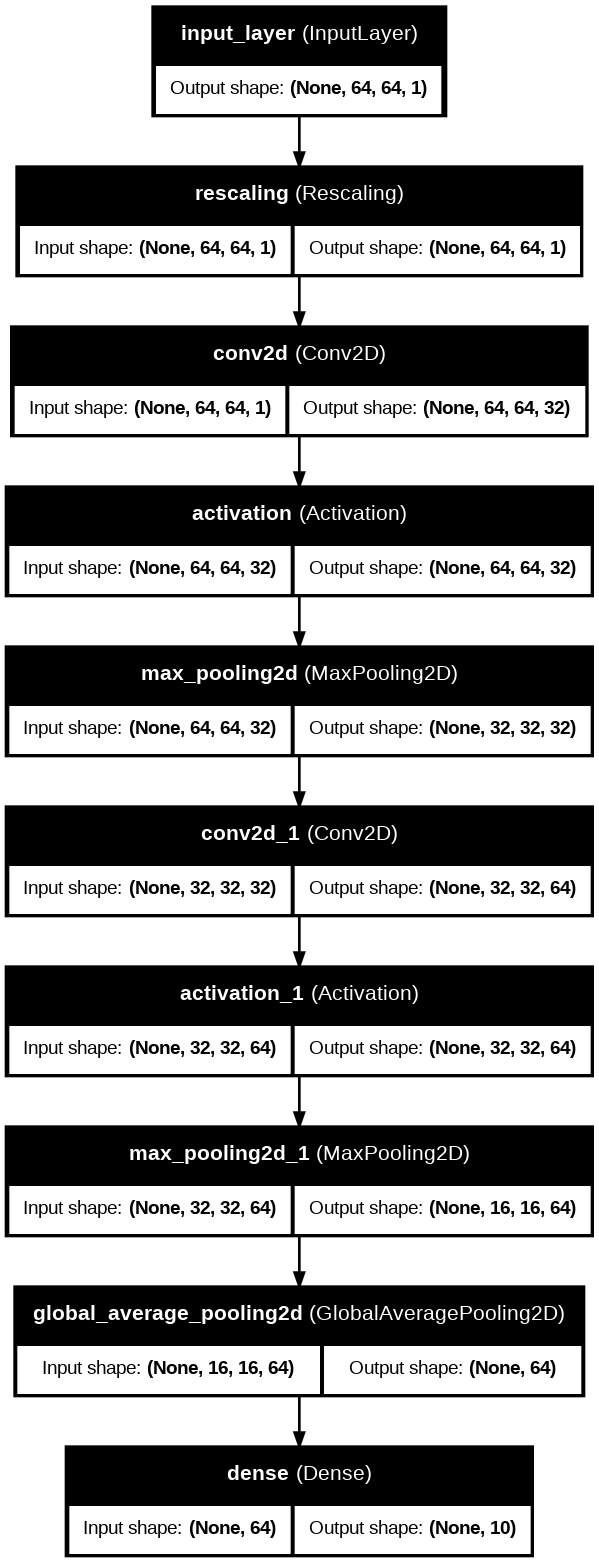

In [ ]:
# Visualize the model architecture as a layer graph
keras.utils.plot_model(
    instantiated_models['Baseline'],
    to_file=os.path.join(VISUALIZATIONS_DIR, 'baseline_architecture.png'),
    show_shapes=True,
    show_layer_names=True,
    dpi=96)

In [ ]:
# Train the network
histories['Baseline'] = run_model_training(
  instantiated_models['Baseline'],
  train_ds, validation_ds,
  epochs=50, patience=10,
  save_name='BaselineCNN')

<IPython.core.display.Javascript object>


Start Training: BaselineCNN
Epoch 1/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 35s 14ms/step - accuracy: 0.3357 - loss: 1.7949 - val_accuracy: 0.4254 - val_loss: 1.6109
Epoch 2/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 27s 12ms/step - accuracy: 0.4485 - loss: 1.5419 - val_accuracy: 0.4823 - val_loss: 1.4740
Epoch 3/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 30s 14ms/step - accuracy: 0.4914 - loss: 1.4434 - val_accuracy: 0.4903 - val_loss: 1.4144
Epoch 4/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 41s 14ms/step - accuracy: 0.5239 - loss: 1.3632 - val_accuracy: 0.5331 - val_loss: 1.3289
Epoch 5/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 31s 14ms/step - accuracy: 0.5479 - loss: 1.3012 - val_accuracy: 0.5571 - val_loss: 1.2888
Epoch 6/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - accuracy: 0.5659 - loss: 1.2562 - val_accuracy: 0.5679 - val_loss: 1.2558
Epoch 7/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 28s 13ms/step - accuracy: 0.5776 - loss: 1.2221 - val_accuracy: 0.5900 - val_loss: 1.2050
Epoch 8/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 27s 1

<IPython.core.display.Javascript object>

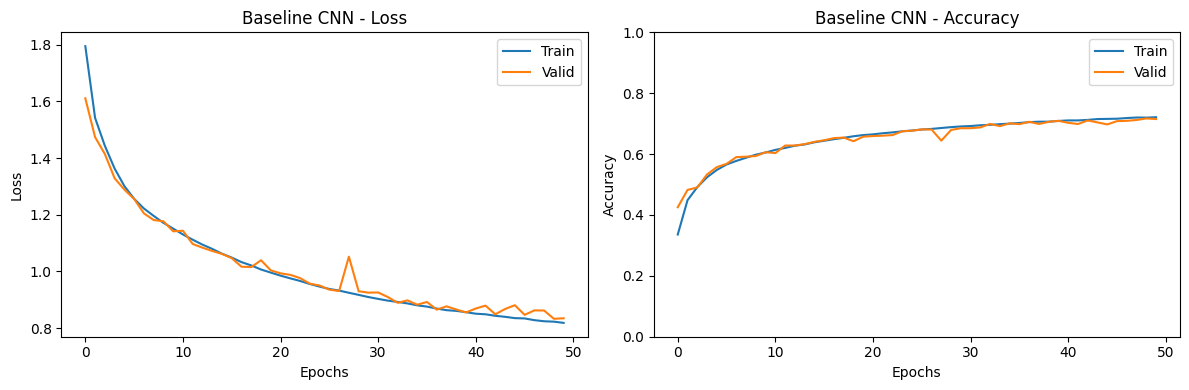

In [ ]:
# Display learning curves
plot_learning_curves(histories['Baseline'], 'Baseline CNN')

In [ ]:
# Display test-set metrics
evaluate_on_testset(instantiated_models['Baseline'], test_ds, 'Baseline CNN',
                    history_dict=histories['Baseline'])

<IPython.core.display.Javascript object>


Results on Test Set for Baseline CNN:
 -> Test Loss:     0.8206
 -> Test Accuracy: 0.7248
 -> Best Val Loss: 0.8328
 -> Best Val Acc:  0.7171



<IPython.core.display.Javascript object>

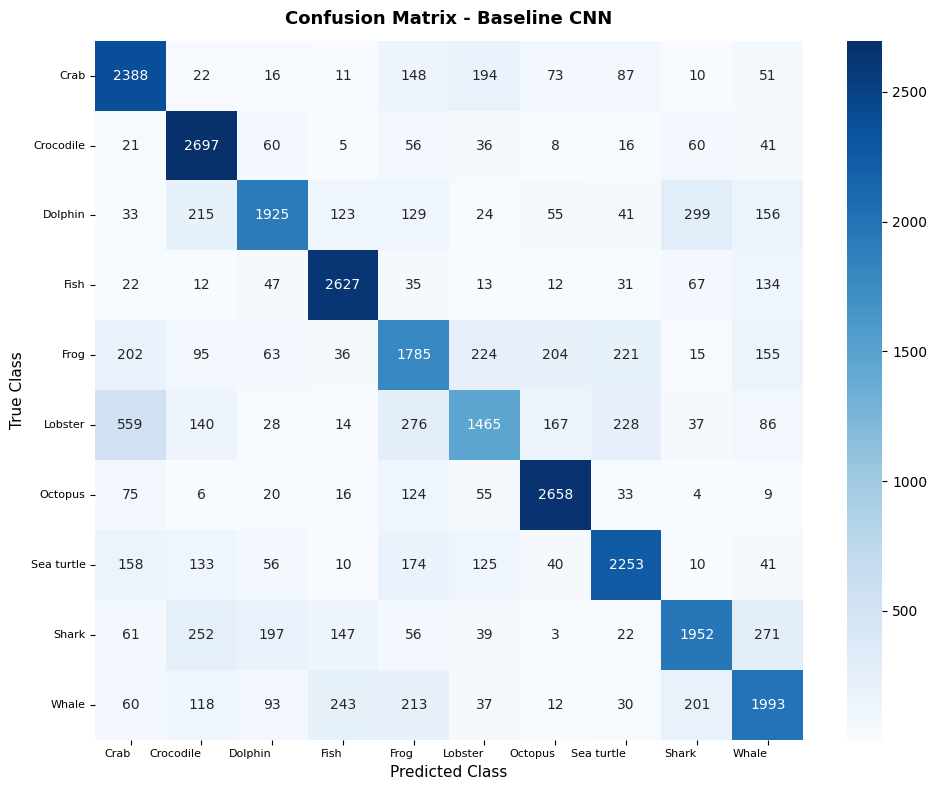

In [ ]:
# Display the confusion matrix
y_true, y_pred = plot_confusion_matrix(
    instantiated_models['Baseline'], test_ds, class_names, 'Baseline CNN')

In [ ]:
# Display the classification report
plot_classification_report(y_true, y_pred, class_names, 'Baseline CNN')

<IPython.core.display.Javascript object>


Classification Report - Baseline CNN:
              precision    recall  f1-score   support

        Crab       0.67      0.80      0.73      3000
   Crocodile       0.73      0.90      0.81      3000
     Dolphin       0.77      0.64      0.70      3000
        Fish       0.81      0.88      0.84      3000
        Frog       0.60      0.59      0.60      3000
     Lobster       0.66      0.49      0.56      3000
     Octopus       0.82      0.89      0.85      3000
  Sea turtle       0.76      0.75      0.76      3000
       Shark       0.74      0.65      0.69      3000
       Whale       0.68      0.66      0.67      3000

    accuracy                           0.72     30000
   macro avg       0.72      0.72      0.72     30000
weighted avg       0.72      0.72      0.72     30000



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

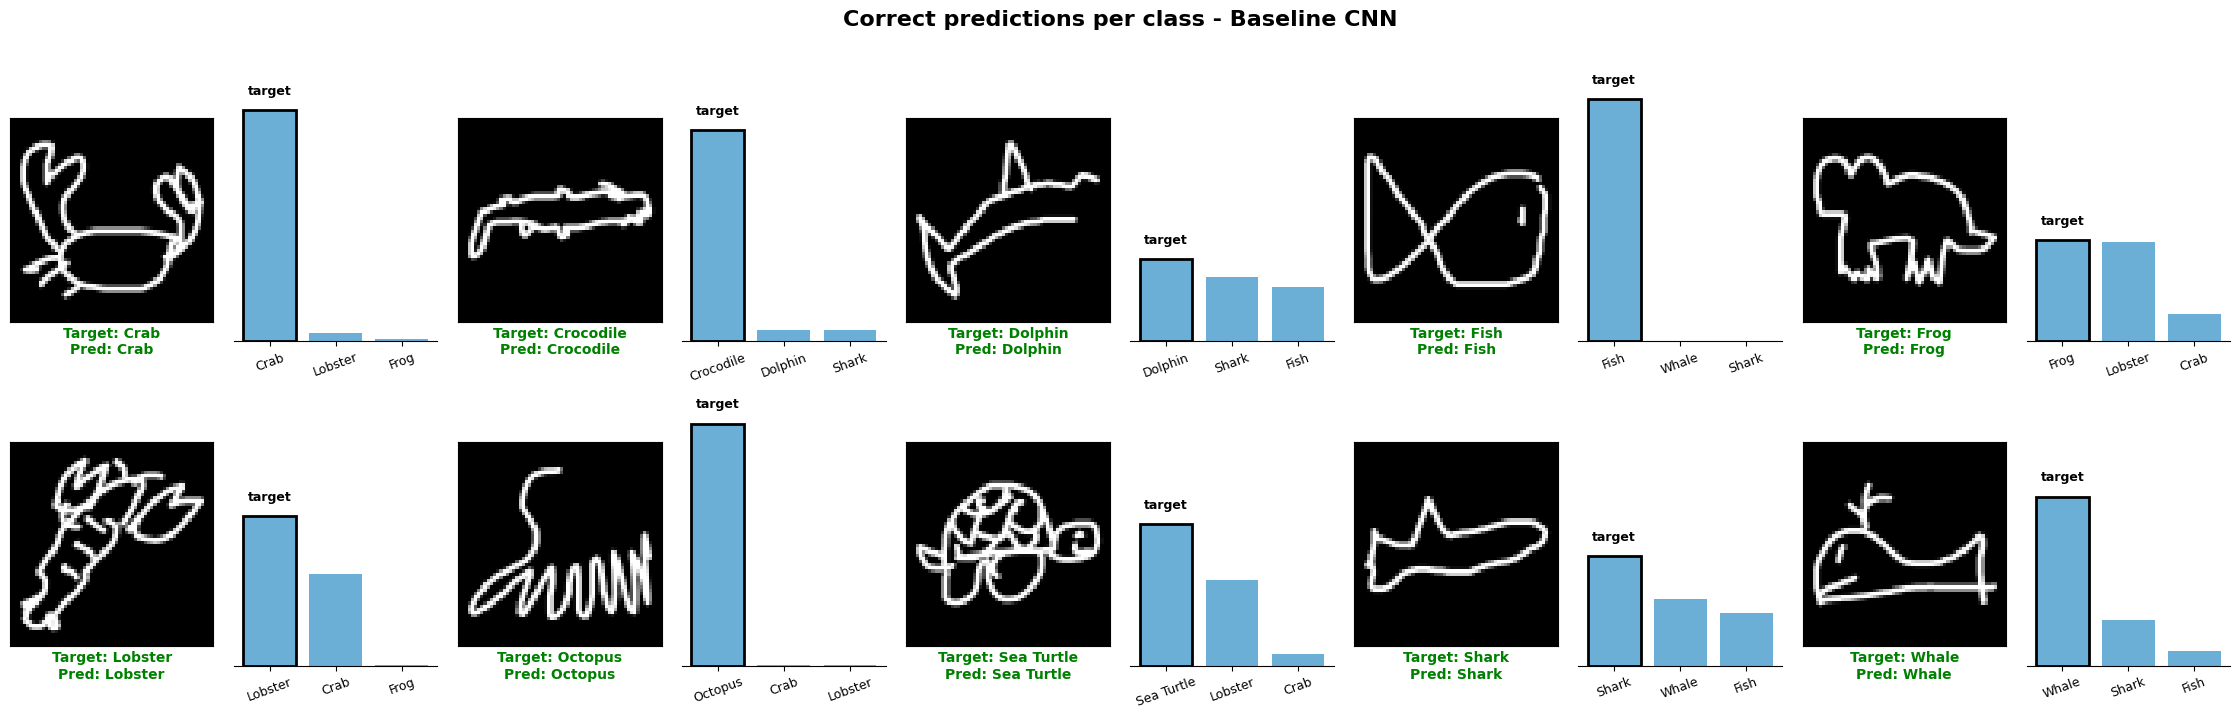

In [ ]:
# Display the prediction grid (correct images) of the Baseline CNN
instantiated_models['Baseline'] = tf.keras.models.load_model(
    os.path.join(MODELS_DIR, 'BaselineCNN.keras'))
x_val, y_val, preds_val = collect_arrays(
    instantiated_models['Baseline'], test_ds)
show_predictions_grid(x_val, y_val, preds_val, class_names,
                      model_label='Baseline CNN', mode='correct')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

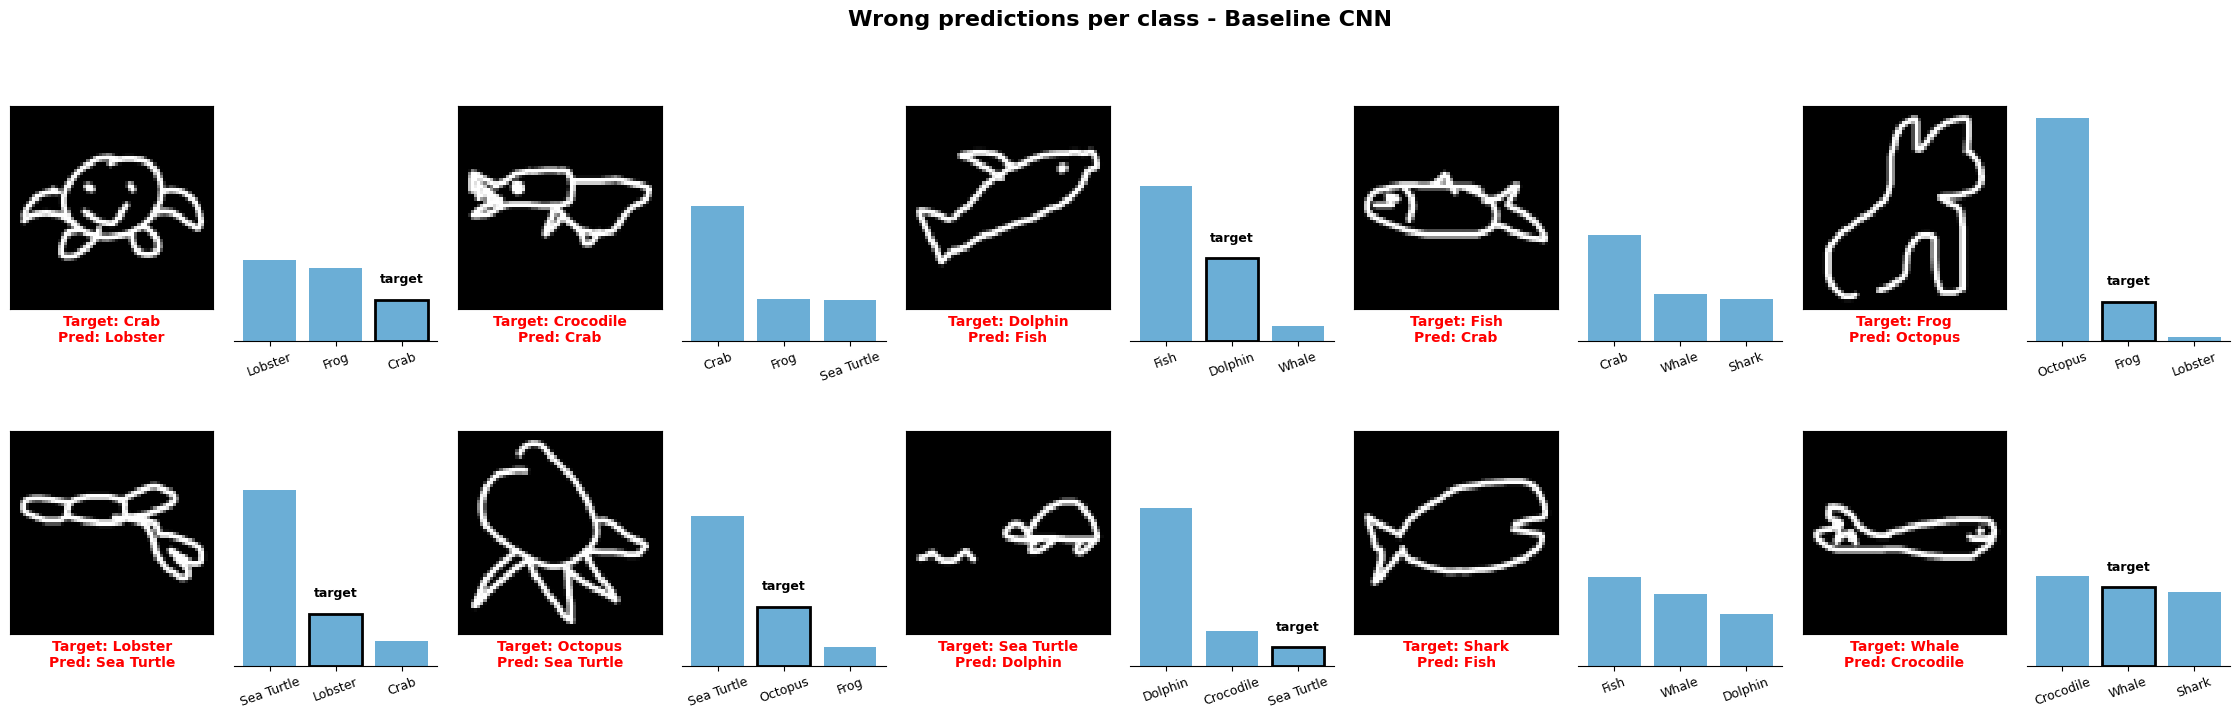

In [ ]:
# Display the prediction grid (wrong images) of the Baseline CNN
show_predictions_grid(x_val, y_val, preds_val, class_names,
                      model_label='Baseline CNN', mode='wrong')

---

#### **4.4.2 Regularized CNN**

In [ ]:
# Instantiate and display the model summary
instantiated_models['Regularization'] = build_regularized_model()
instantiated_models['Regularization'].summary()

<IPython.core.display.Javascript object>

Model: "Regularized_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 111,882 (437.04 KB)

 Trainable params: 111,178 (434.29 KB)

 Non-trainable params: 704 (2.75 KB)

<IPython.core.display.Javascript object>

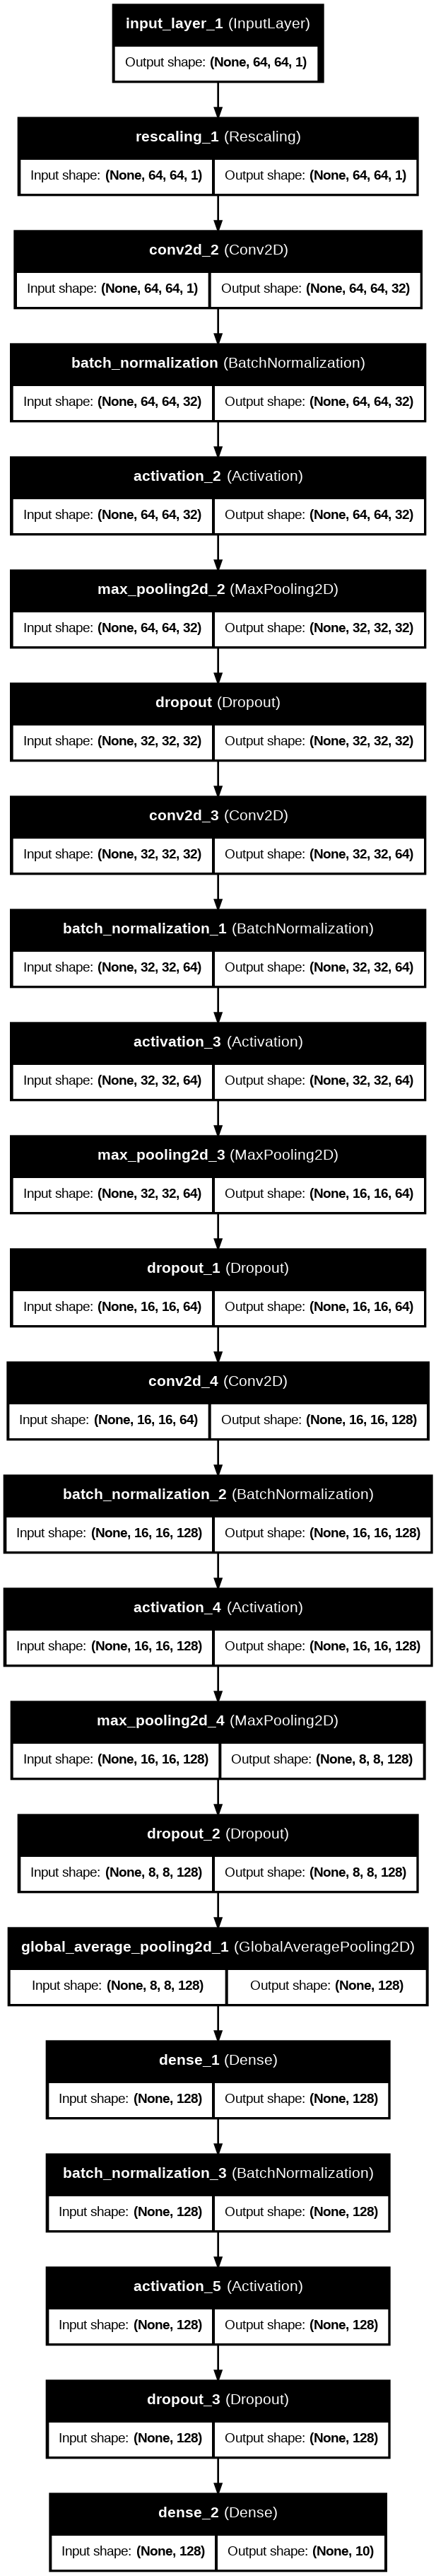

In [ ]:
# Visualize the model architecture as a layer graph
keras.utils.plot_model(
    instantiated_models['Regularization'],
    to_file=os.path.join(VISUALIZATIONS_DIR, 'regularized_architecture.png'),
    show_shapes=True,
    show_layer_names=True,
    dpi=96)

In [ ]:
# Train the network
histories['Regularization'] = run_model_training(
  instantiated_models['Regularization'],
  train_ds, validation_ds,
  epochs=50, patience=10,
  save_name='RegularizedCNN')

<IPython.core.display.Javascript object>


Start Training: RegularizedCNN
Epoch 1/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 52s 19ms/step - accuracy: 0.5536 - loss: 1.2644 - val_accuracy: 0.4845 - val_loss: 1.5844
Epoch 2/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 33s 15ms/step - accuracy: 0.7190 - loss: 0.8230 - val_accuracy: 0.7373 - val_loss: 0.7572
Epoch 3/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 34s 15ms/step - accuracy: 0.7589 - loss: 0.7127 - val_accuracy: 0.7599 - val_loss: 0.6847
Epoch 4/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 34s 15ms/step - accuracy: 0.7784 - loss: 0.6585 - val_accuracy: 0.8259 - val_loss: 0.5141
Epoch 5/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - accuracy: 0.7906 - loss: 0.6249 - val_accuracy: 0.8241 - val_loss: 0.5087
Epoch 6/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 33s 15ms/step - accuracy: 0.7981 - loss: 0.6009 - val_accuracy: 0.8343 - val_loss: 0.4838
Epoch 7/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 41s 15ms/step - accuracy: 0.8036 - loss: 0.5840 - val_accuracy: 0.8509 - val_loss: 0.4342
Epoch 8/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 34

<IPython.core.display.Javascript object>

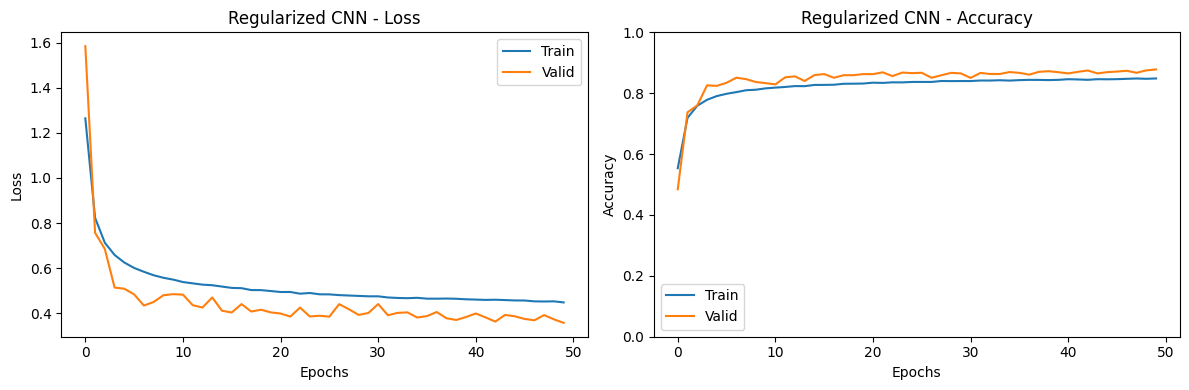

In [ ]:
# Display learning curves
plot_learning_curves(histories['Regularization'], 'Regularized CNN')

In [ ]:
# Display test-set metrics
evaluate_on_testset(instantiated_models['Regularization'],
                    test_ds, 'Regularized CNN', history_dict=histories['Regularization'])

<IPython.core.display.Javascript object>


Results on Test Set for Regularized CNN:
 -> Test Loss:     0.3553
 -> Test Accuracy: 0.8790
 -> Best Val Loss: 0.3574
 -> Best Val Acc:  0.8781



<IPython.core.display.Javascript object>

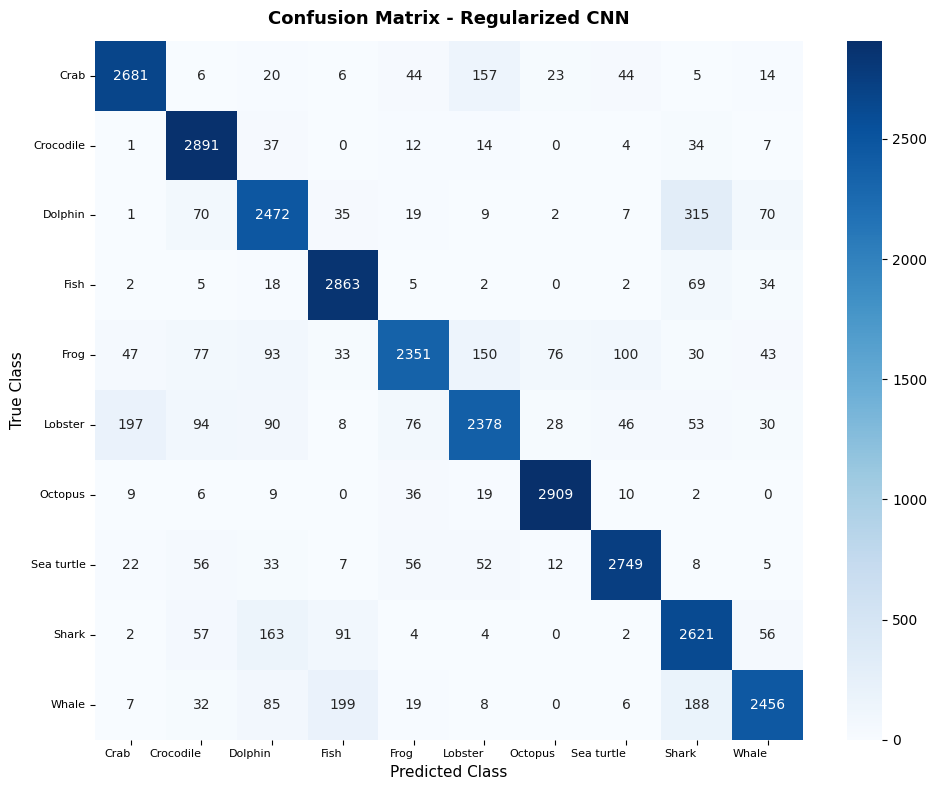

In [ ]:
# Display the confusion matrix
y_true, y_pred = plot_confusion_matrix(
    instantiated_models['Regularization'], test_ds, class_names, 'Regularized CNN')

In [ ]:
# Display the classification report
plot_classification_report(y_true, y_pred, class_names, 'Regularized CNN')

<IPython.core.display.Javascript object>


Classification Report - Regularized CNN:
              precision    recall  f1-score   support

        Crab       0.90      0.89      0.90      3000
   Crocodile       0.88      0.96      0.92      3000
     Dolphin       0.82      0.82      0.82      3000
        Fish       0.88      0.95      0.92      3000
        Frog       0.90      0.78      0.84      3000
     Lobster       0.85      0.79      0.82      3000
     Octopus       0.95      0.97      0.96      3000
  Sea turtle       0.93      0.92      0.92      3000
       Shark       0.79      0.87      0.83      3000
       Whale       0.90      0.82      0.86      3000

    accuracy                           0.88     30000
   macro avg       0.88      0.88      0.88     30000
weighted avg       0.88      0.88      0.88     30000



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

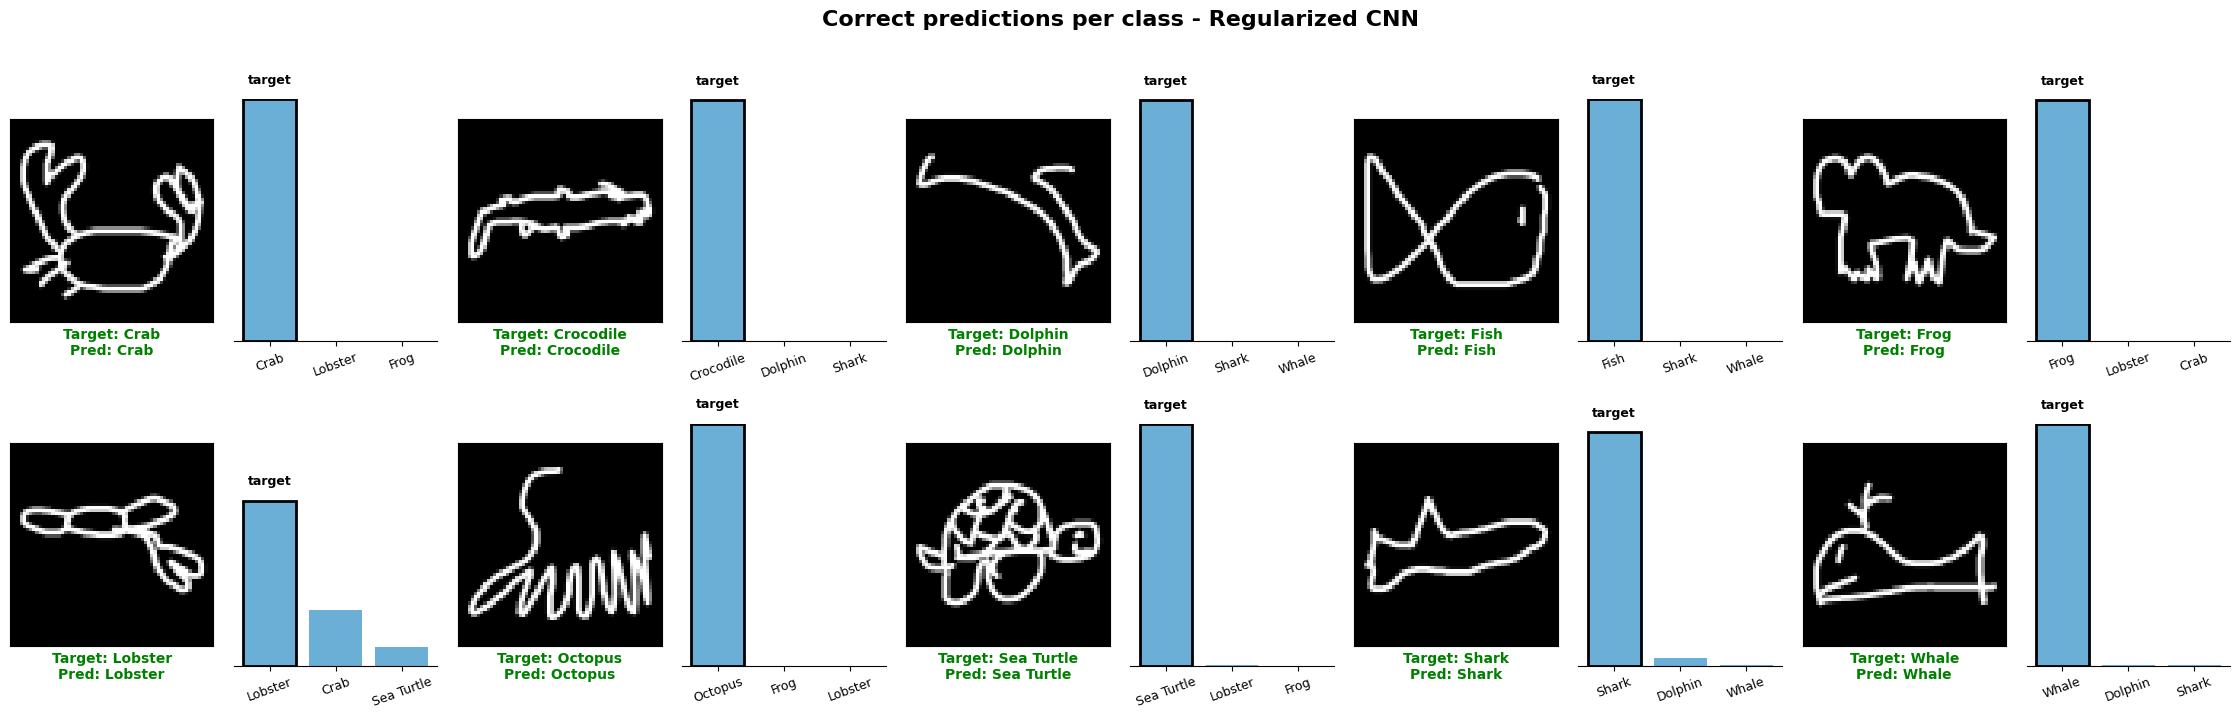

In [ ]:
# Display the prediction grid (correct images) of the Regularized CNN
instantiated_models['Regularization'] = tf.keras.models.load_model(
    os.path.join(MODELS_DIR, 'RegularizedCNN.keras'))
x_val, y_val, preds_val = collect_arrays(
    instantiated_models['Regularization'], test_ds)
show_predictions_grid(x_val, y_val, preds_val, class_names,
                      model_label='Regularized CNN', mode='correct')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

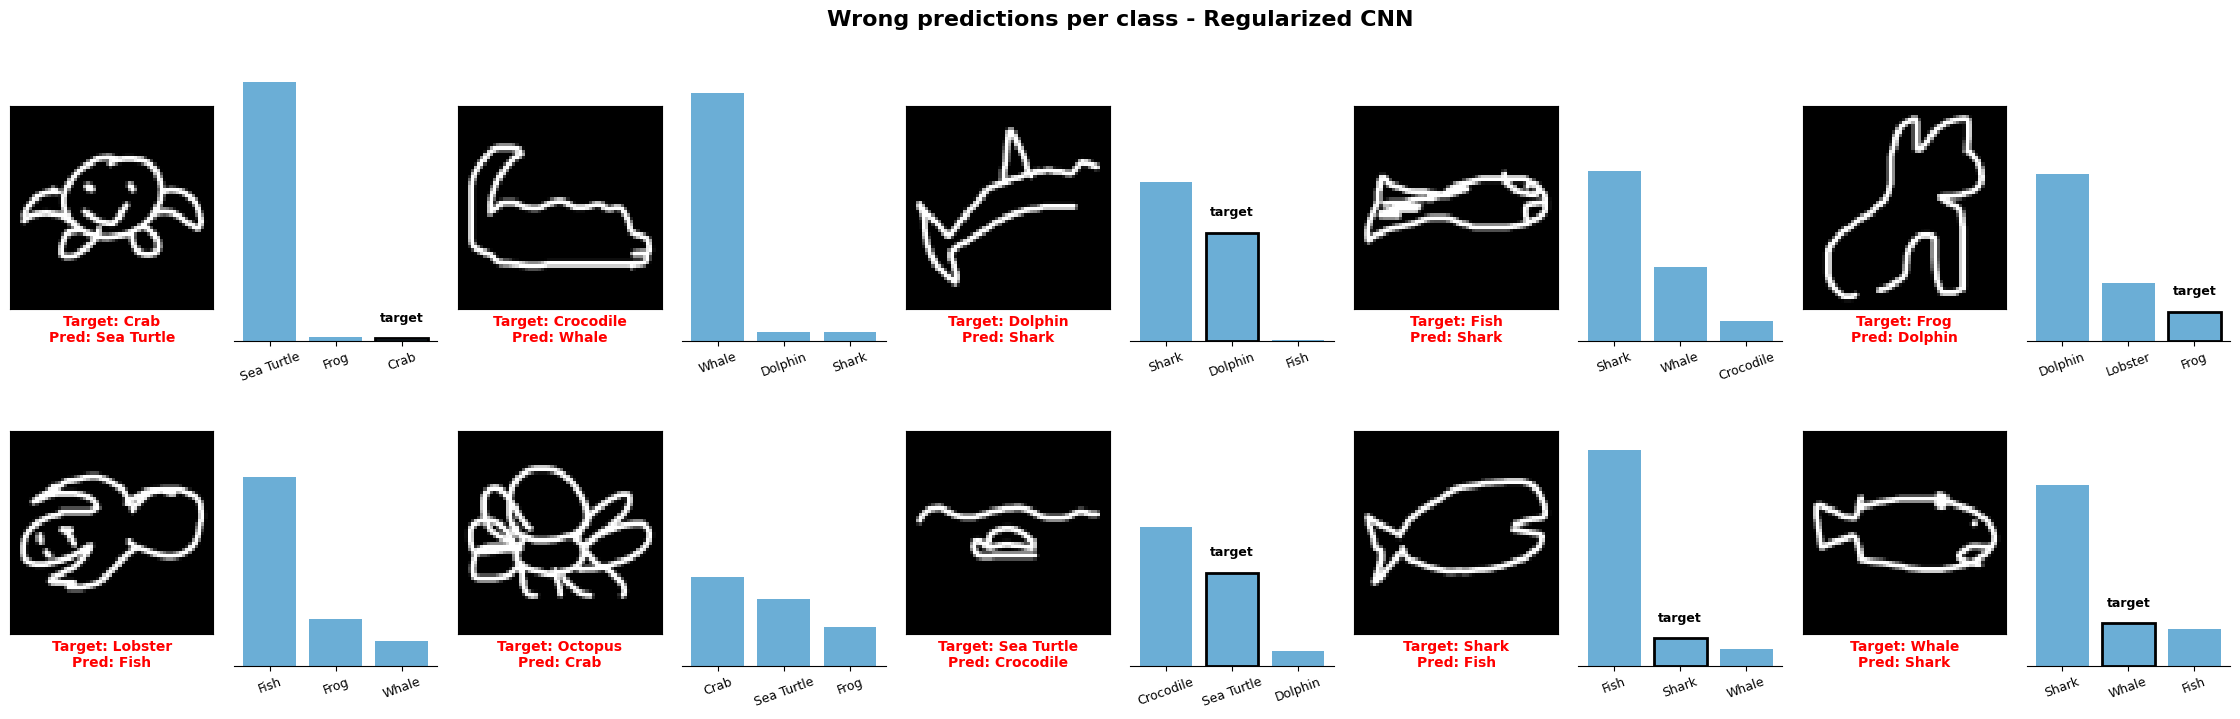

In [ ]:
# Display the prediction grid (wrong images) of the Regularized CNN
show_predictions_grid(x_val, y_val, preds_val, class_names,
                      model_label='Regularized CNN', mode='wrong')

---

#### **4.4.3 Data Augmentation CNN**

In [ ]:
# Instantiate and display the model summary
instantiated_models['Augmentation'] = build_augmented_model()
instantiated_models['Augmentation'].summary()

<IPython.core.display.Javascript object>

Model: "Augmented_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │             

 Total params: 111,882 (437.04 KB)

 Trainable params: 111,178 (434.29 KB)

 Non-trainable params: 704 (2.75 KB)

<IPython.core.display.Javascript object>

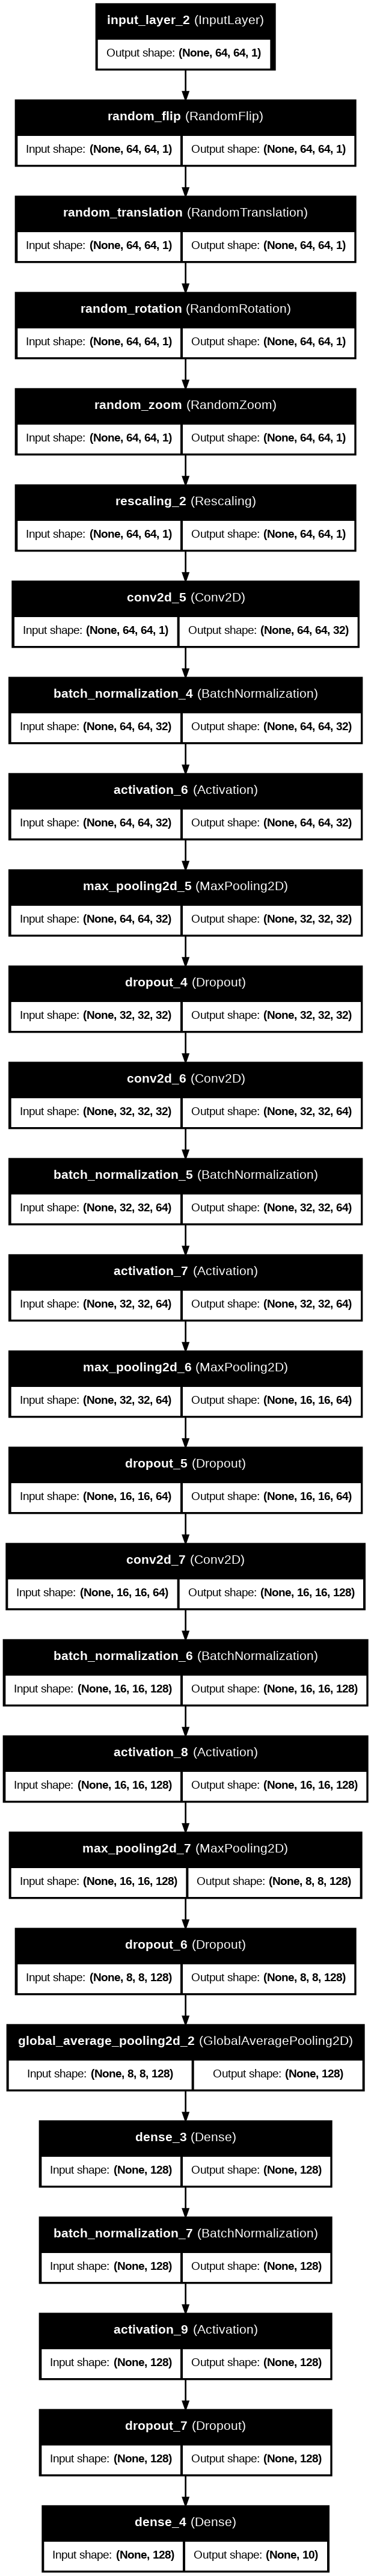

In [ ]:
# Visualize the model architecture as a layer graph
keras.utils.plot_model(
    instantiated_models['Augmentation'],
    to_file=os.path.join(VISUALIZATIONS_DIR, 'augmented_architecture.png'),
    show_shapes=True,
    show_layer_names=True,
    dpi=96)

In [ ]:
# Train the network
histories['Augmentation'] = run_model_training(
  instantiated_models['Augmentation'],
  train_ds, validation_ds,
  epochs=50, patience=10,
  save_name='AugmentedCNN')

<IPython.core.display.Javascript object>


Start Training: AugmentedCNN
Epoch 1/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 86s 36ms/step - accuracy: 0.5020 - loss: 1.3930 - val_accuracy: 0.6202 - val_loss: 1.1430
Epoch 2/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 77s 35ms/step - accuracy: 0.6739 - loss: 0.9427 - val_accuracy: 0.7112 - val_loss: 0.8410
Epoch 3/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 75s 34ms/step - accuracy: 0.7172 - loss: 0.8255 - val_accuracy: 0.7190 - val_loss: 0.7917
Epoch 4/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 77s 35ms/step - accuracy: 0.7391 - loss: 0.7695 - val_accuracy: 0.7498 - val_loss: 0.7099
Epoch 5/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 77s 35ms/step - accuracy: 0.7499 - loss: 0.7378 - val_accuracy: 0.6390 - val_loss: 1.1774
Epoch 6/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 76s 35ms/step - accuracy: 0.7563 - loss: 0.7153 - val_accuracy: 0.7628 - val_loss: 0.6777
Epoch 7/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 81s 35ms/step - accuracy: 0.7632 - loss: 0.6982 - val_accuracy: 0.7920 - val_loss: 0.5909
Epoch 8/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 77s 

<IPython.core.display.Javascript object>

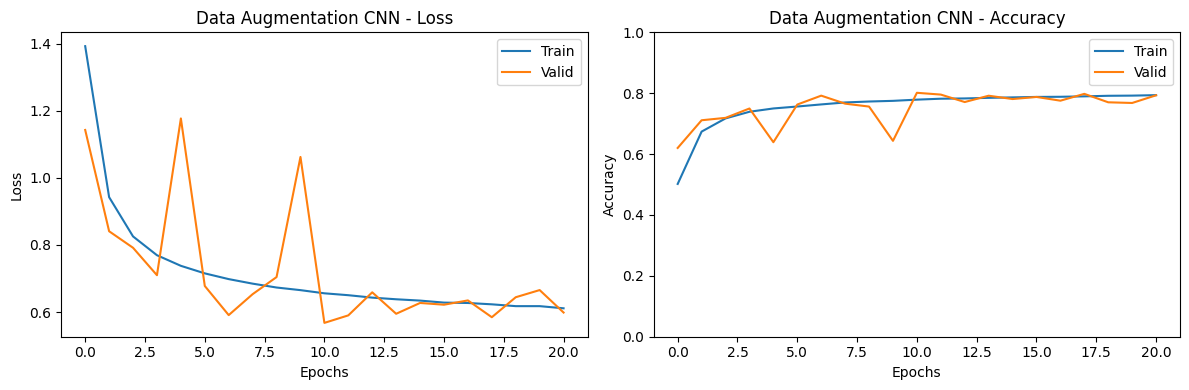

In [ ]:
# Display learning curves
plot_learning_curves(histories['Augmentation'], 'Data Augmentation CNN')

In [ ]:
# Display test-set metrics
evaluate_on_testset(instantiated_models['Augmentation'],
                    test_ds, 'Data Augmentation CNN', history_dict=histories['Augmentation'])

<IPython.core.display.Javascript object>


Results on Test Set for Data Augmentation CNN:
 -> Test Loss:     0.5630
 -> Test Accuracy: 0.8059
 -> Best Val Loss: 0.5676
 -> Best Val Acc:  0.8014



<IPython.core.display.Javascript object>

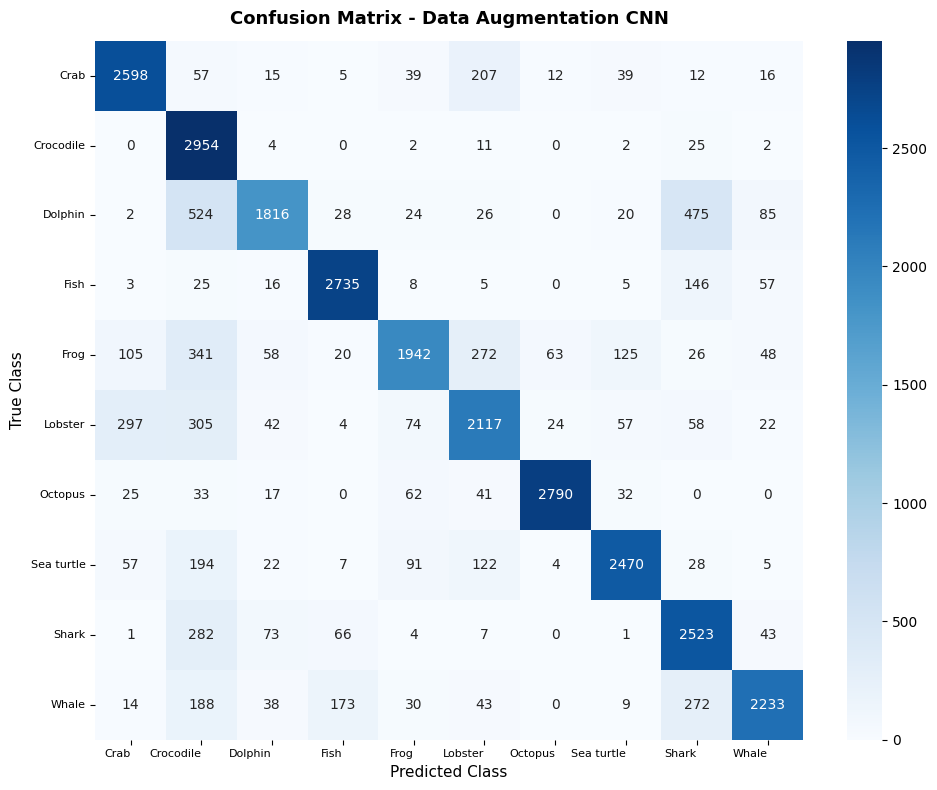

In [ ]:
# Display the confusion matrix
y_true, y_pred = plot_confusion_matrix(
    instantiated_models['Augmentation'], test_ds, class_names, 'Data Augmentation CNN')

In [ ]:
# Display the classification report
plot_classification_report(y_true, y_pred, class_names, 'Data Augmentation CNN')

<IPython.core.display.Javascript object>


Classification Report - Data Augmentation CNN:
              precision    recall  f1-score   support

        Crab       0.84      0.87      0.85      3000
   Crocodile       0.60      0.98      0.75      3000
     Dolphin       0.86      0.61      0.71      3000
        Fish       0.90      0.91      0.91      3000
        Frog       0.85      0.65      0.74      3000
     Lobster       0.74      0.71      0.72      3000
     Octopus       0.96      0.93      0.95      3000
  Sea turtle       0.89      0.82      0.86      3000
       Shark       0.71      0.84      0.77      3000
       Whale       0.89      0.74      0.81      3000

    accuracy                           0.81     30000
   macro avg       0.83      0.81      0.81     30000
weighted avg       0.83      0.81      0.81     30000



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

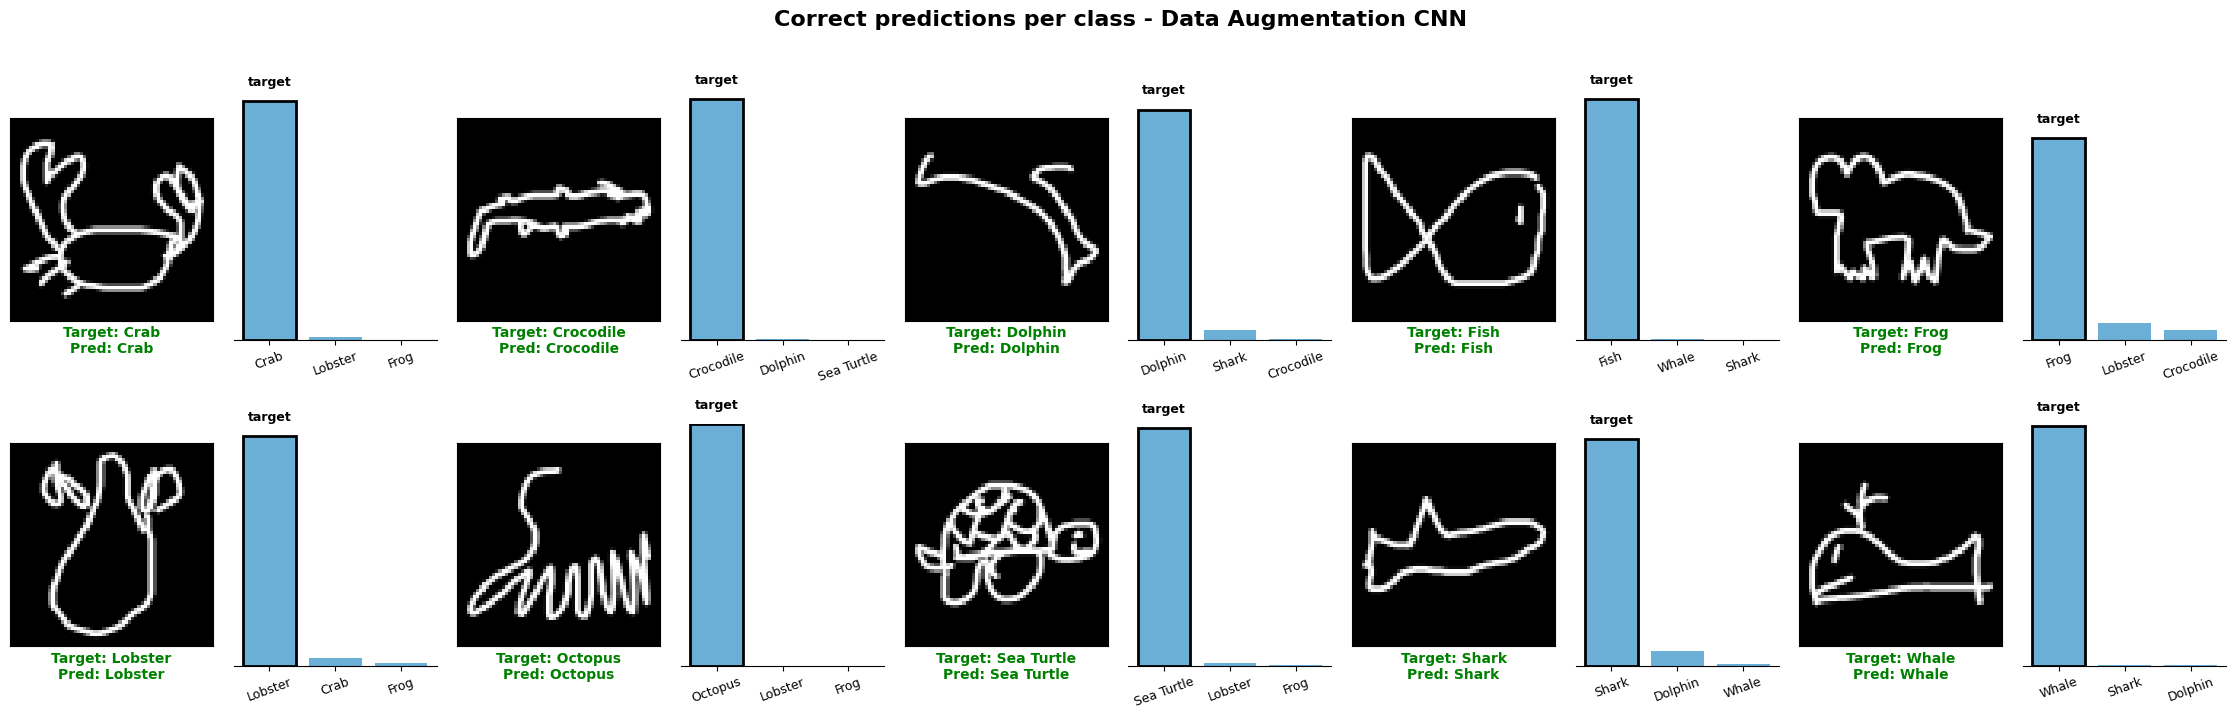

In [ ]:
# Display the prediction grid (correct images) of the Data Augmentation CNN
instantiated_models['Augmentation'] = tf.keras.models.load_model(
    os.path.join(MODELS_DIR, 'AugmentedCNN.keras'))
x_val, y_val, preds_val = collect_arrays(
    instantiated_models['Augmentation'], test_ds)
show_predictions_grid(x_val, y_val, preds_val, class_names,
                      model_label='Data Augmentation CNN', mode='correct')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

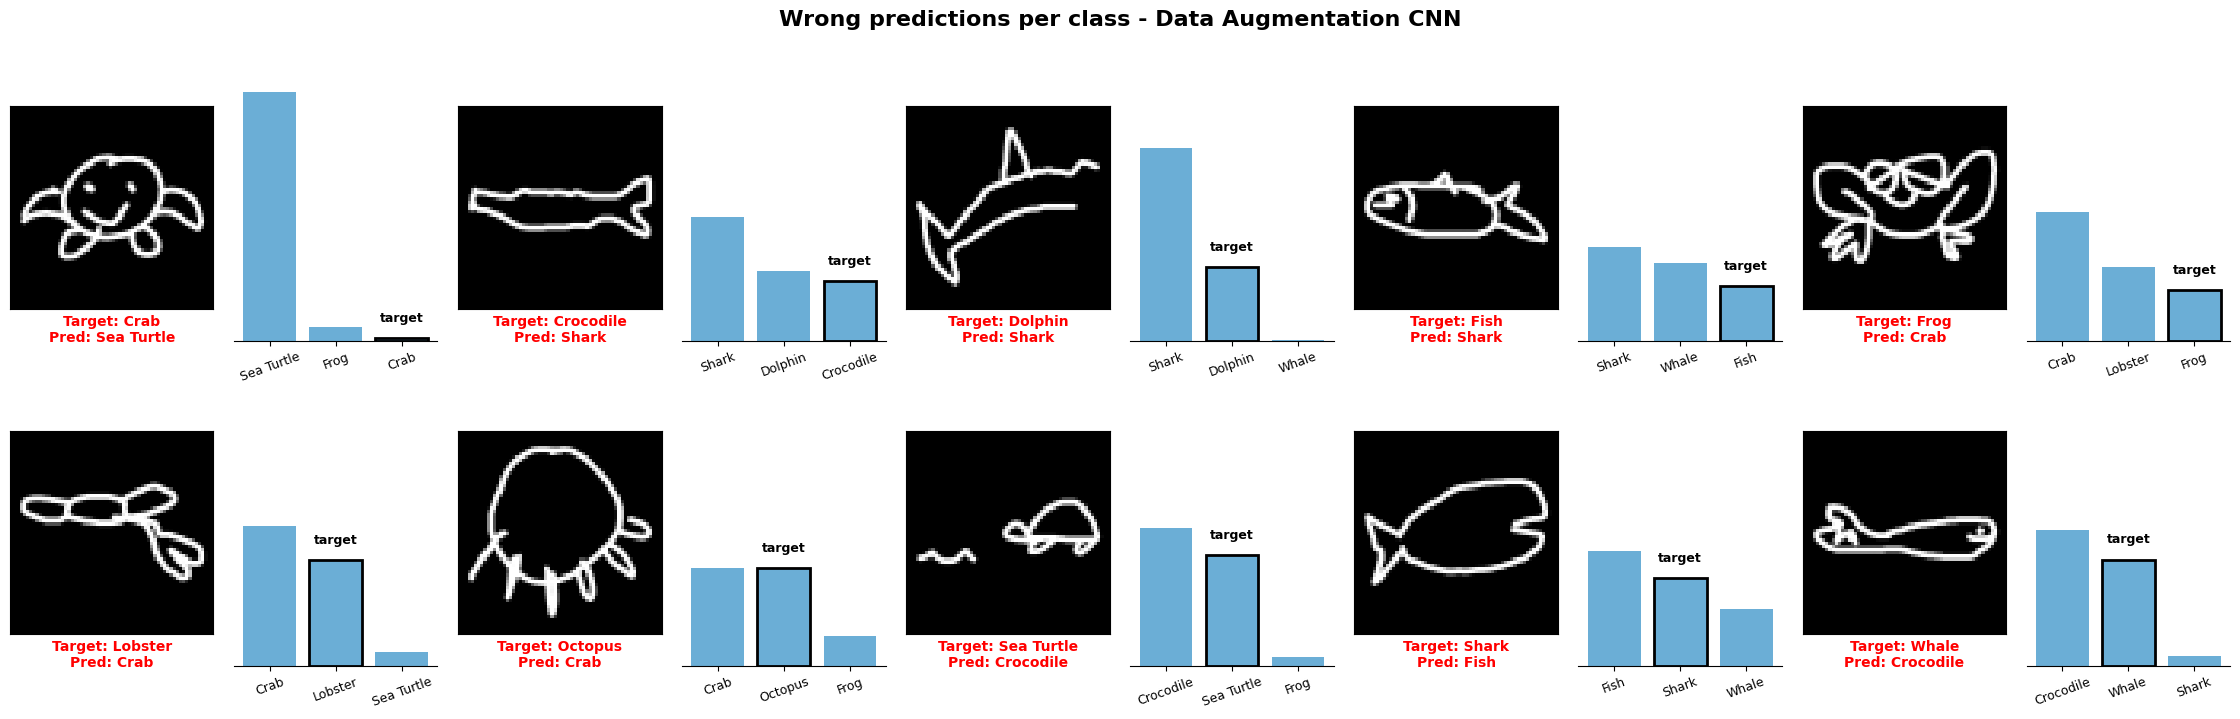

In [ ]:
# Display the prediction grid (wrong images) of the Data Augmentation CNN
show_predictions_grid(x_val, y_val, preds_val, class_names,
                      model_label='Data Augmentation CNN', mode='wrong')

---

#### **4.4.4 Hyperparameter Optimization (Keras Tuner)**

`max_trials=12` allows Keras Tuner to effectively explore 12 random configurations (33%) among the 36 possible combinations.

In [ ]:
# Perform hyperparameter search
class ProgressRandomSearch(kt.RandomSearch):
    def search(self, *args, **kwargs):
        self.pbar = tqdm(
            total=self.oracle.max_trials,
            desc='Hyperparameter Search',
            unit='trial'
        )
        super().search(*args, **kwargs)
        self.pbar.close()

    def on_trial_end(self, trial):
        super().on_trial_end(trial)
        self.pbar.update(1)


print('\nStarting Hyperparameter Search via Keras Tuner - RandomSearch')
tuner = ProgressRandomSearch(
    build_tunable_model,
    objective='val_accuracy',
    max_trials=12,
    executions_per_trial=1,
    directory='keras_tuner_logs',
    project_name='quickdraw_tuning',
    overwrite=True)

search_early_stop = keras.callbacks.EarlyStopping(
    monitor='val_accuracy', patience=2)

tuner.search(train_ds, epochs=8,
             validation_data=validation_ds,
             callbacks=[search_early_stop],
             verbose=0)

<IPython.core.display.Javascript object>


Starting Hyperparameter Search via Keras Tuner - RandomSearch


Hyperparameter Search:   0%|          | 0/12 [00:00<?, ?trial/s]

In [ ]:
# Display the optimal value for each hyperparameter
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print('\nBest parameters found:')
print(f" Conv Filters: {best_hps.get('filters')}")
print(f" Dropout Rate: {best_hps.get('dropout_rate'):.2f}")
print(f" Dense Units: {best_hps.get('dense_units')}")
print(f" Learning Rate: {best_hps.get('learning_rate')}")

<IPython.core.display.Javascript object>


Best parameters found:
 Conv Filters: 96
 Dropout Rate: 0.20
 Dense Units: 256
 Learning Rate: 0.001


In [ ]:
# Build optimised model and display summary
instantiated_models['Tuned'] = tuner.hypermodel.build(best_hps)
instantiated_models['Tuned'].summary()

<IPython.core.display.Javascript object>

Model: "Tunable_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 96)     │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 64, 64, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32, 32, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 192)    │       166,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 192)    │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 192)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 192)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16, 16, 192)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 384)    │       663,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 384)    │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16, 16, 384)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 384)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 8, 8, 384)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 384)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 935,818 (3.57 MB)

 Trainable params: 933,962 (3.56 MB)

 Non-trainable params: 1,856 (7.25 KB)

<IPython.core.display.Javascript object>

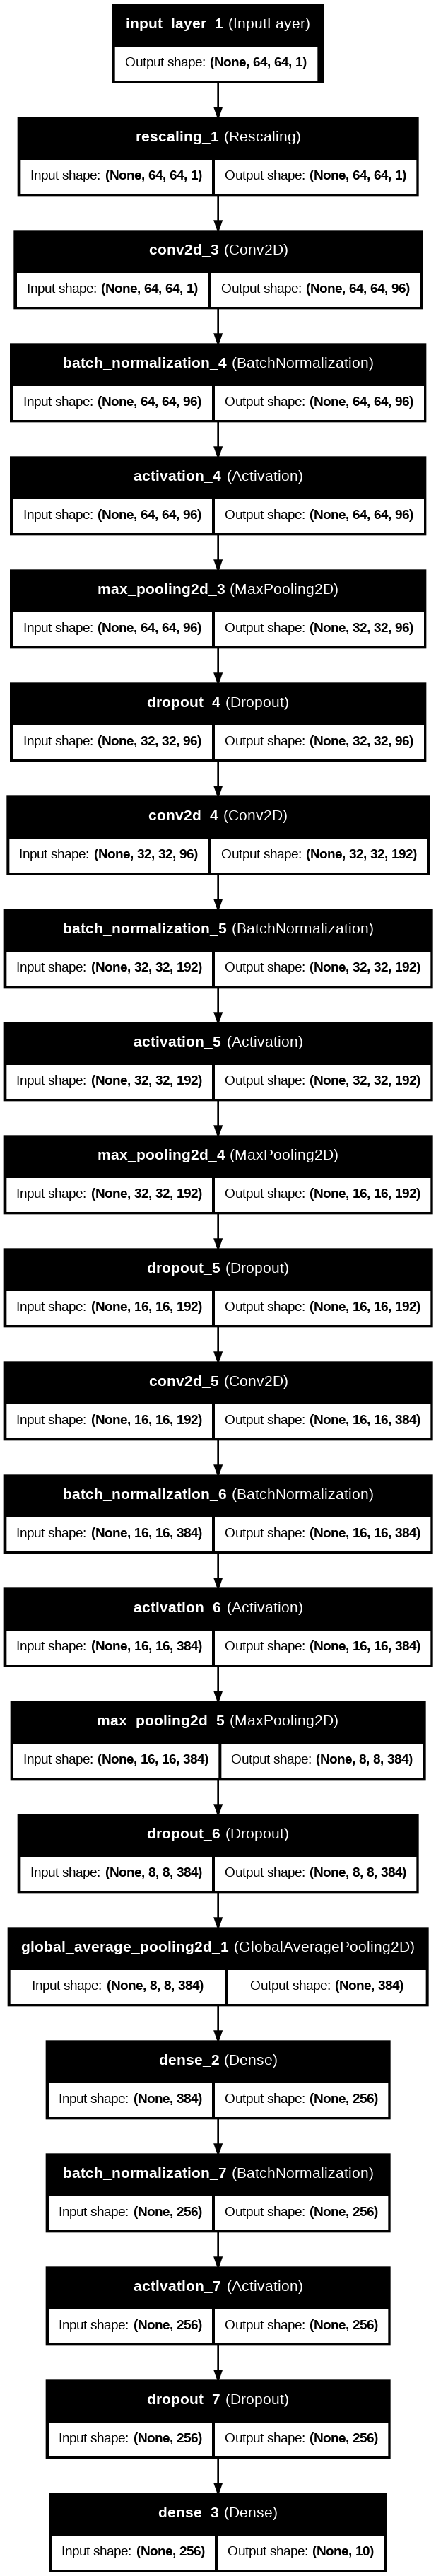

In [ ]:
# Visualize the Tuned model architecture as a layer graph
keras.utils.plot_model(
    instantiated_models['Tuned'],
    to_file=os.path.join(VISUALIZATIONS_DIR, 'tuned_architecture.png'),
    show_shapes=True,
    show_layer_names=True,
    dpi=96)

In [ ]:
# Perform final training with optimal hyperparameters
best_lr = best_hps.get('learning_rate')

histories['Tuned'] = run_model_training(
  instantiated_models['Tuned'],
  train_ds, validation_ds,
  epochs=50, patience=10,
  save_name='TunedCNN',
  learning_rate=best_lr)

<IPython.core.display.Javascript object>


Start Training: TunedCNN
Epoch 1/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 111s 47ms/step - accuracy: 0.7044 - loss: 0.8467 - val_accuracy: 0.7293 - val_loss: 0.7915
Epoch 2/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 96s 44ms/step - accuracy: 0.8091 - loss: 0.5571 - val_accuracy: 0.7384 - val_loss: 0.8116
Epoch 3/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 97s 44ms/step - accuracy: 0.8356 - loss: 0.4811 - val_accuracy: 0.7067 - val_loss: 0.8787
Epoch 4/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 97s 44ms/step - accuracy: 0.8510 - loss: 0.4364 - val_accuracy: 0.8193 - val_loss: 0.5551
Epoch 5/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 97s 44ms/step - accuracy: 0.8622 - loss: 0.4019 - val_accuracy: 0.8422 - val_loss: 0.4772
Epoch 6/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 97s 44ms/step - accuracy: 0.8712 - loss: 0.3738 - val_accuracy: 0.8077 - val_loss: 0.6046
Epoch 7/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 97s 44ms/step - accuracy: 0.8793 - loss: 0.3503 - val_accuracy: 0.8558 - val_loss: 0.4278
Epoch 8/50
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 98s 45m

<IPython.core.display.Javascript object>

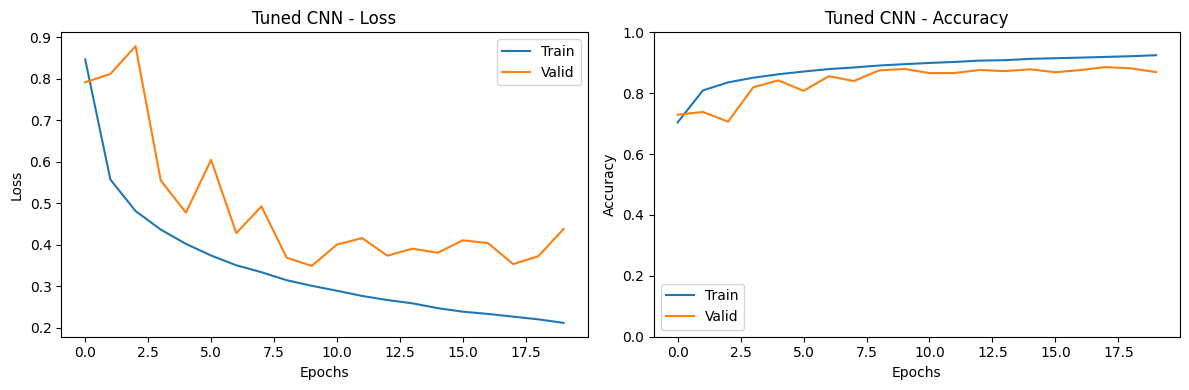

In [ ]:
# Display learning curves
plot_learning_curves(histories['Tuned'], 'Tuned CNN')

In [ ]:
# Display test-set metrics
evaluate_on_testset(instantiated_models['Tuned'], test_ds, 'Tuned CNN',
                    history_dict=histories['Tuned'])

<IPython.core.display.Javascript object>


Results on Test Set for Tuned CNN:
 -> Test Loss:     0.3514
 -> Test Accuracy: 0.8789
 -> Best Val Loss: 0.3488
 -> Best Val Acc:  0.8858



<IPython.core.display.Javascript object>

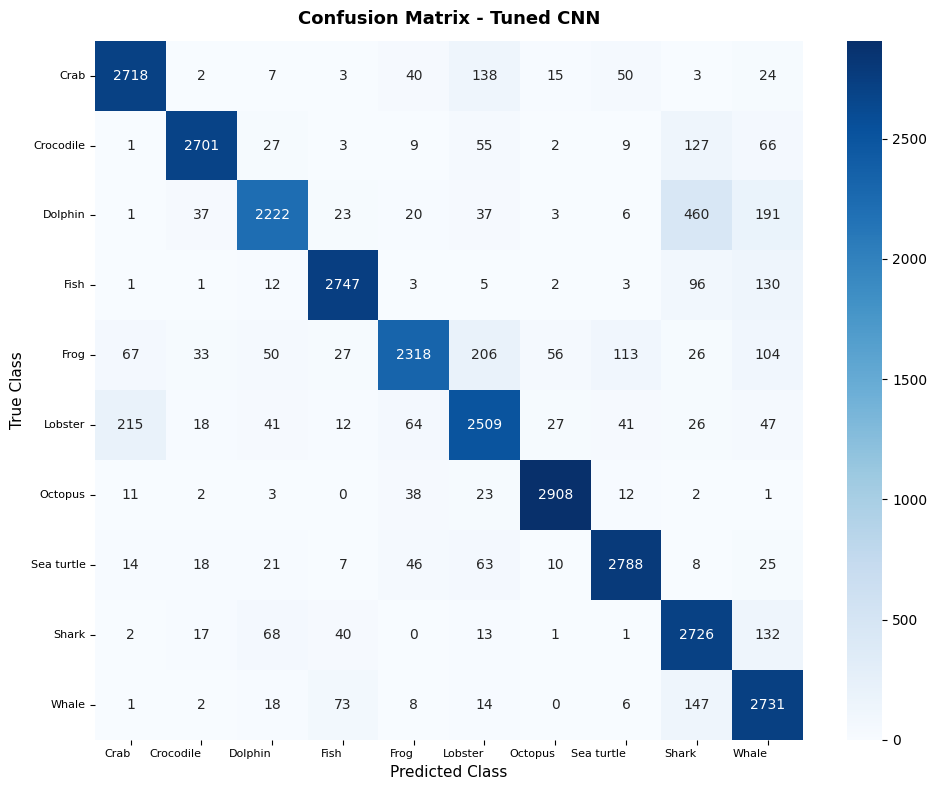

In [ ]:
# Display the confusion matrix
y_true, y_pred = plot_confusion_matrix(
    instantiated_models['Tuned'], test_ds, class_names, 'Tuned CNN')

In [ ]:
# Display the classification report
plot_classification_report(y_true, y_pred, class_names, 'Tuned CNN')

<IPython.core.display.Javascript object>


Classification Report - Tuned CNN:
              precision    recall  f1-score   support

        Crab       0.90      0.91      0.90      3000
   Crocodile       0.95      0.90      0.93      3000
     Dolphin       0.90      0.74      0.81      3000
        Fish       0.94      0.92      0.93      3000
        Frog       0.91      0.77      0.84      3000
     Lobster       0.82      0.84      0.83      3000
     Octopus       0.96      0.97      0.97      3000
  Sea turtle       0.92      0.93      0.92      3000
       Shark       0.75      0.91      0.82      3000
       Whale       0.79      0.91      0.85      3000

    accuracy                           0.88     30000
   macro avg       0.88      0.88      0.88     30000
weighted avg       0.88      0.88      0.88     30000



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

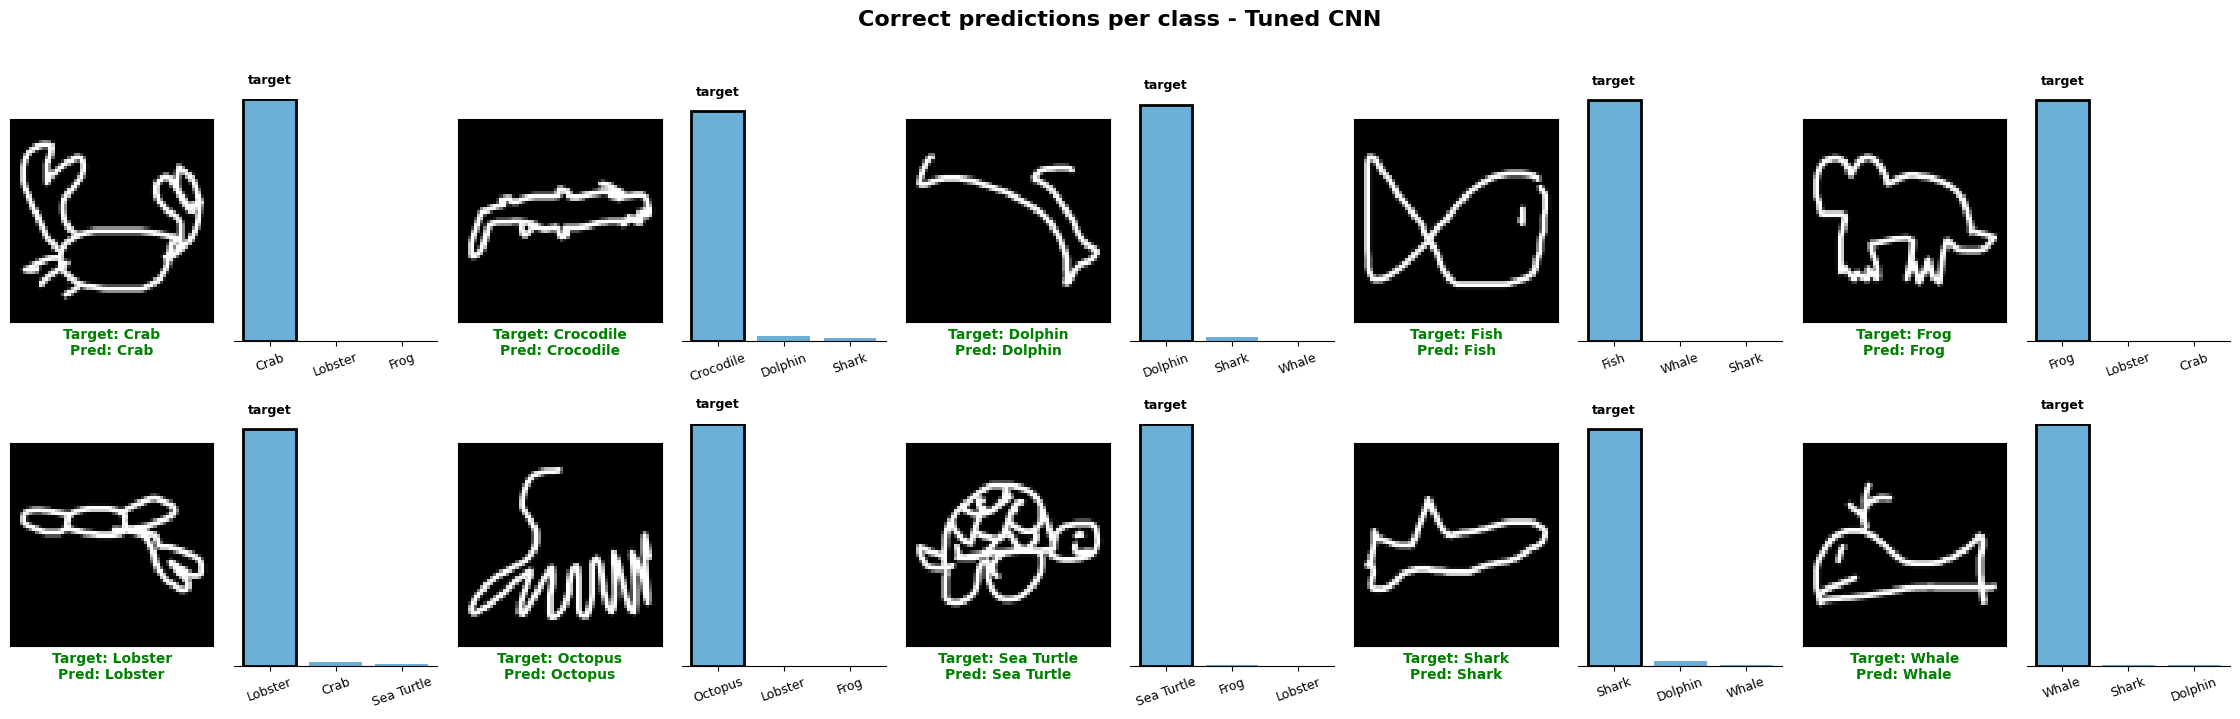

In [ ]:
# Display the prediction grid (correct images) of the Tuned CNN
instantiated_models['Tuned'] = tf.keras.models.load_model(
    os.path.join(MODELS_DIR, 'TunedCNN.keras'))
x_val, y_val, preds_val = collect_arrays(instantiated_models['Tuned'], test_ds)
show_predictions_grid(x_val, y_val, preds_val, class_names,
                      model_label='Tuned CNN', mode='correct')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

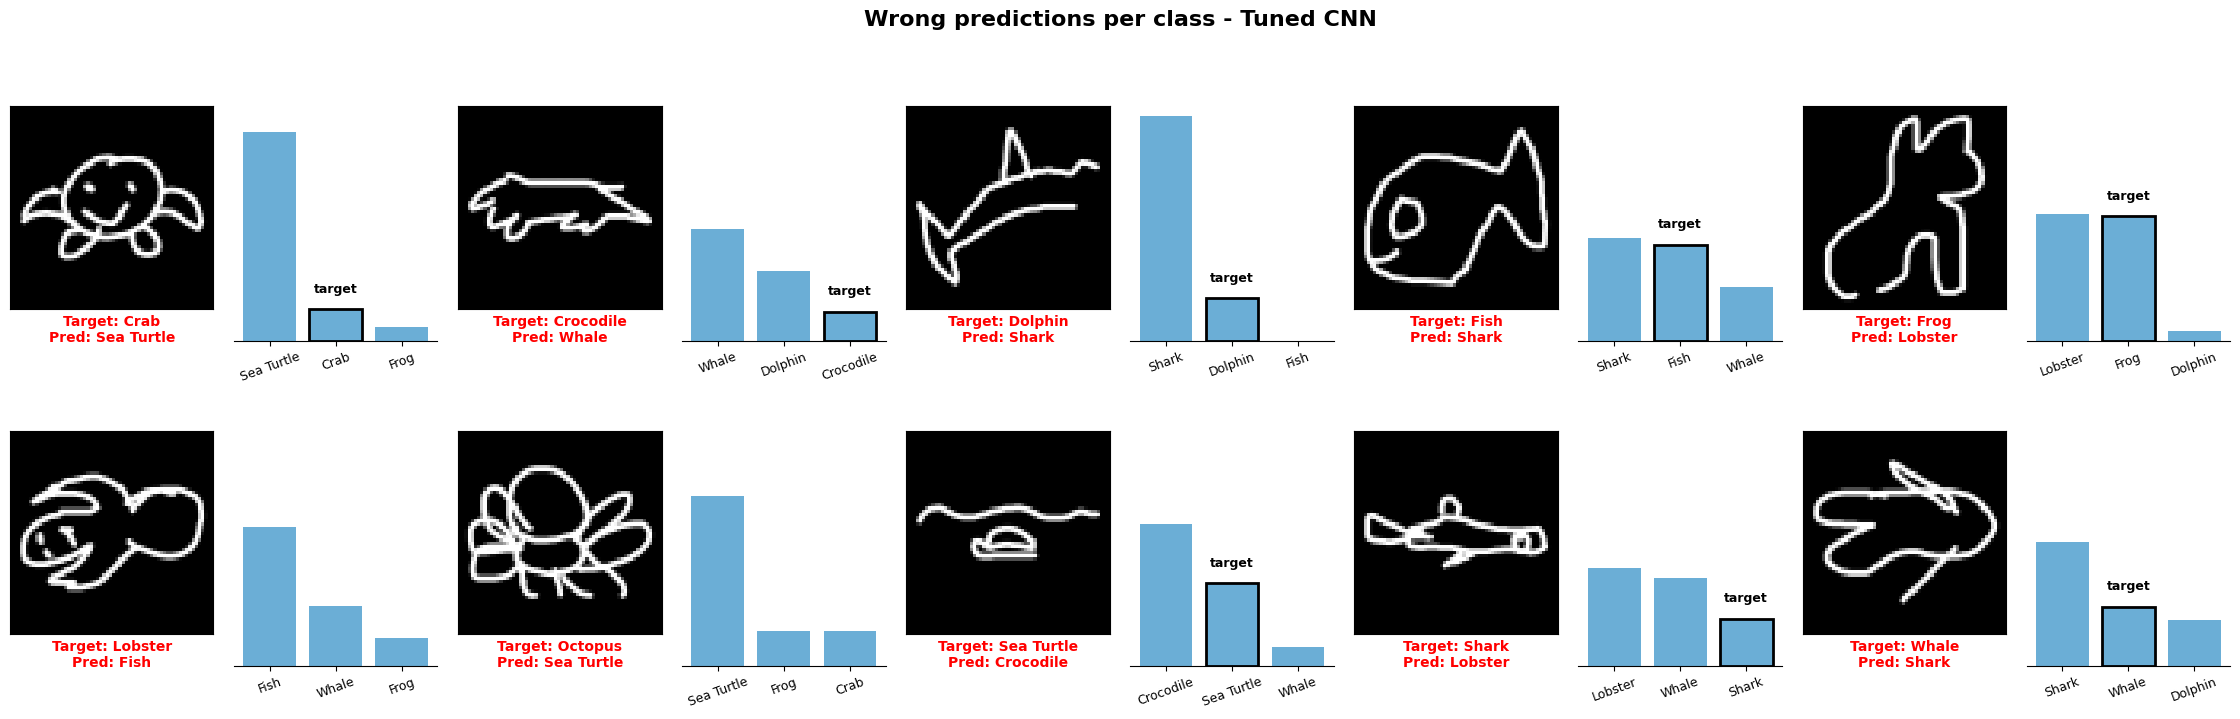

In [ ]:
# Display the prediction grid (wrong images) of the Tuned CNN
show_predictions_grid(x_val, y_val, preds_val, class_names,
                      model_label='Tuned CNN', mode='wrong')

---

#### **4.4.5 Transfer Learning (MobileNetV2)**

We use `MobileNetV2`, a pretrained model on ImageNet, as the backbone for transfer learning. The model expects 64x64 RGB inputs, which must be preprocessed using `mobilenet_v2.preprocess_input` to match the normalization used during pretraining. Firstly, the network is loaded with `include_top=False` so that a custom classification head can be attached, and all backbone layers are initially frozen to prevent retraining and preserve the pretrained feature extractor.

In [ ]:
# Instantiate and display the model summary
instantiated_models['Transfer'] = build_transfer_model()
instantiated_models['Transfer'].summary()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/tmp/ipykernel_1815/1393053255.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_net = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "TransferLearning_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,754 (9.25 MB)

 Trainable params: 165,514 (646.54 KB)

 Non-trainable params: 2,258,240 (8.61 MB)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

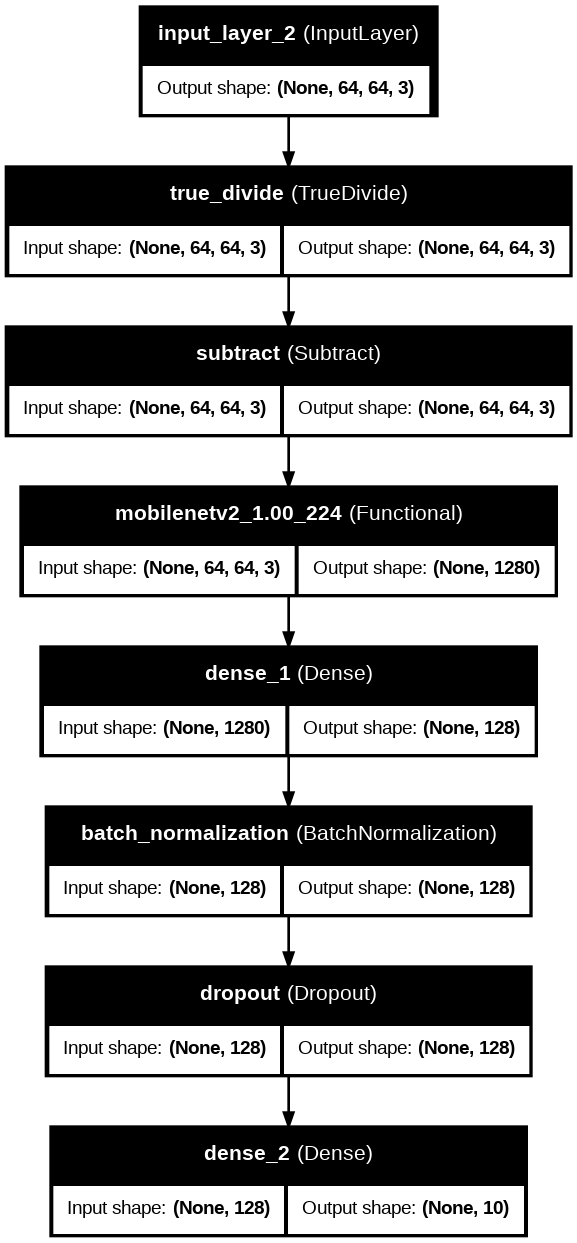

In [ ]:
# Visualize the model architecture as a layer graph
keras.utils.plot_model(
    instantiated_models['Transfer'],
    to_file=os.path.join(VISUALIZATIONS_DIR, 'transfer_architecture.png'),
    show_shapes=True,
    show_layer_names=True,
    dpi=96)

In [ ]:
# Train the network (fewer epochs needed thanks to pretrained features)
histories['Transfer'] = run_model_training(
  instantiated_models['Transfer'],
  train_ds_rgb, validation_ds_rgb,
  epochs=20, patience=5,
  save_name='TransferCNN')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Start Training: TransferCNN
Epoch 1/20
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 79s 28ms/step - accuracy: 0.6715 - loss: 0.9665 - val_accuracy: 0.7146 - val_loss: 0.8248
Epoch 2/20
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 44s 20ms/step - accuracy: 0.7110 - loss: 0.8386 - val_accuracy: 0.7271 - val_loss: 0.7916
Epoch 3/20
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 42s 19ms/step - accuracy: 0.7199 - loss: 0.8072 - val_accuracy: 0.7340 - val_loss: 0.7723
Epoch 4/20
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 36s 17ms/step - accuracy: 0.7275 - loss: 0.7863 - val_accuracy: 0.7327 - val_loss: 0.7706
Epoch 5/20
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 41s 17ms/step - accuracy: 0.7331 - loss: 0.7702 - val_accuracy: 0.7409 - val_loss: 0.7496
Epoch 6/20
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 43s 20ms/step - accuracy: 0.7362 - loss: 0.7586 - val_accuracy: 0.7415 - val_loss: 0.7444
Epoch 7/20
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.7408 - loss: 0.7446 - val_accuracy: 0.7424 - val_loss: 0.7436
Epoch 8/20
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 78s 1

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

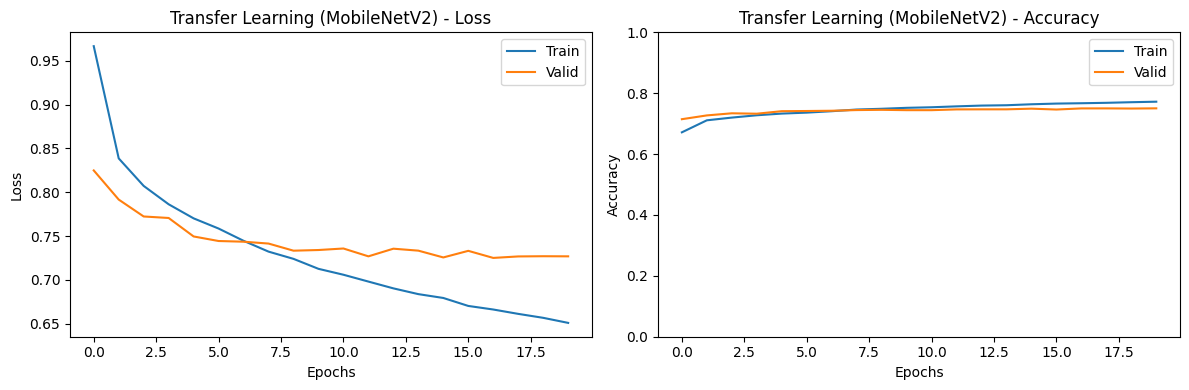

In [ ]:
# Display learning curves
plot_learning_curves(histories['Transfer'], 'Transfer Learning (MobileNetV2)')

In [ ]:
# Display test-set metrics
evaluate_on_testset(instantiated_models['Transfer'], test_ds_rgb, 'Transfer Learning (MobileNetV2)')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Results on Test Set for Transfer Learning (MobileNetV2):
 -> Test Loss: 0.7202
 -> Test Accuracy: 0.7521



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

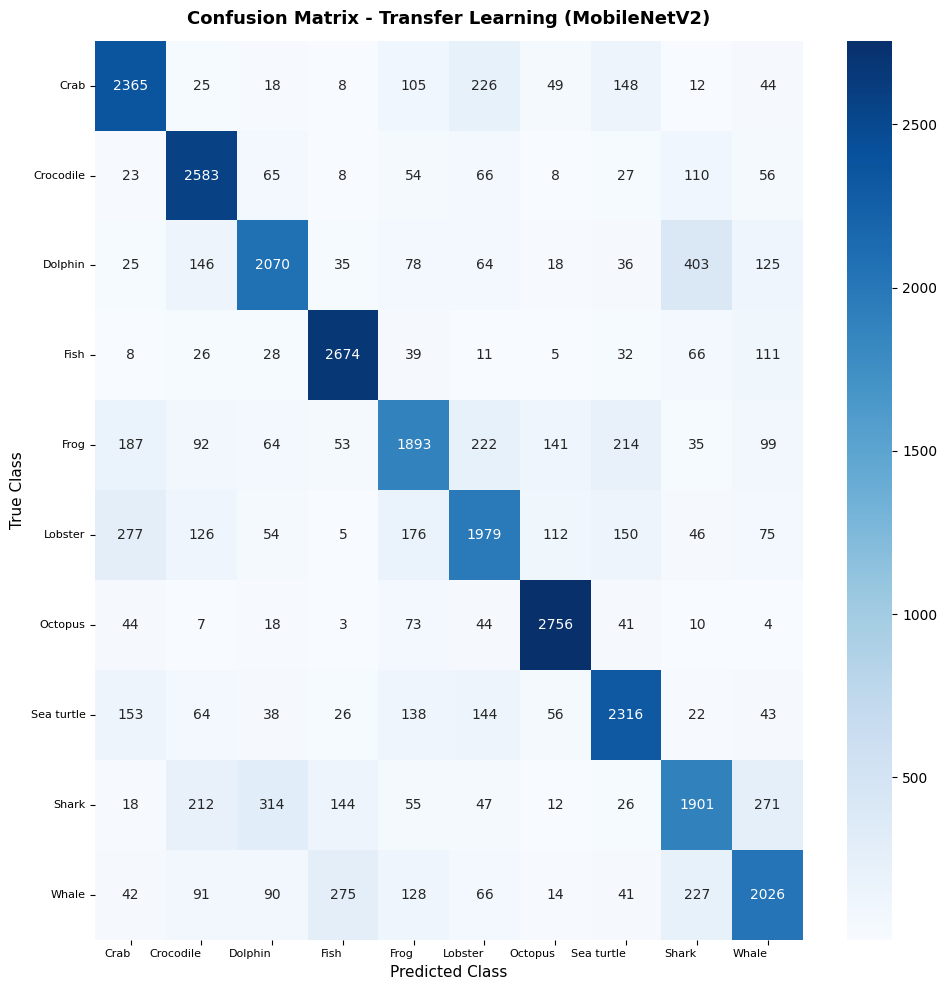

In [ ]:
# Display the confusion matrix
y_true, y_pred = plot_confusion_matrix(
    instantiated_models['Transfer'], test_ds_rgb, class_names, 'Transfer Learning (MobileNetV2)')

In [ ]:
# Display the classification report
plot_classification_report(y_true, y_pred, class_names, 'Transfer Learning (MobileNetV2)')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Classification Report - Transfer Learning (MobileNetV2):
              precision    recall  f1-score   support

        Crab       0.75      0.79      0.77      3000
   Crocodile       0.77      0.86      0.81      3000
     Dolphin       0.75      0.69      0.72      3000
        Fish       0.83      0.89      0.86      3000
        Frog       0.69      0.63      0.66      3000
     Lobster       0.69      0.66      0.67      3000
     Octopus       0.87      0.92      0.89      3000
  Sea turtle       0.76      0.77      0.77      3000
       Shark       0.67      0.63      0.65      3000
       Whale       0.71      0.68      0.69      3000

    accuracy                           0.75     30000
   macro avg       0.75      0.75      0.75     30000
weighted avg       0.75      0.75      0.75     30000



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

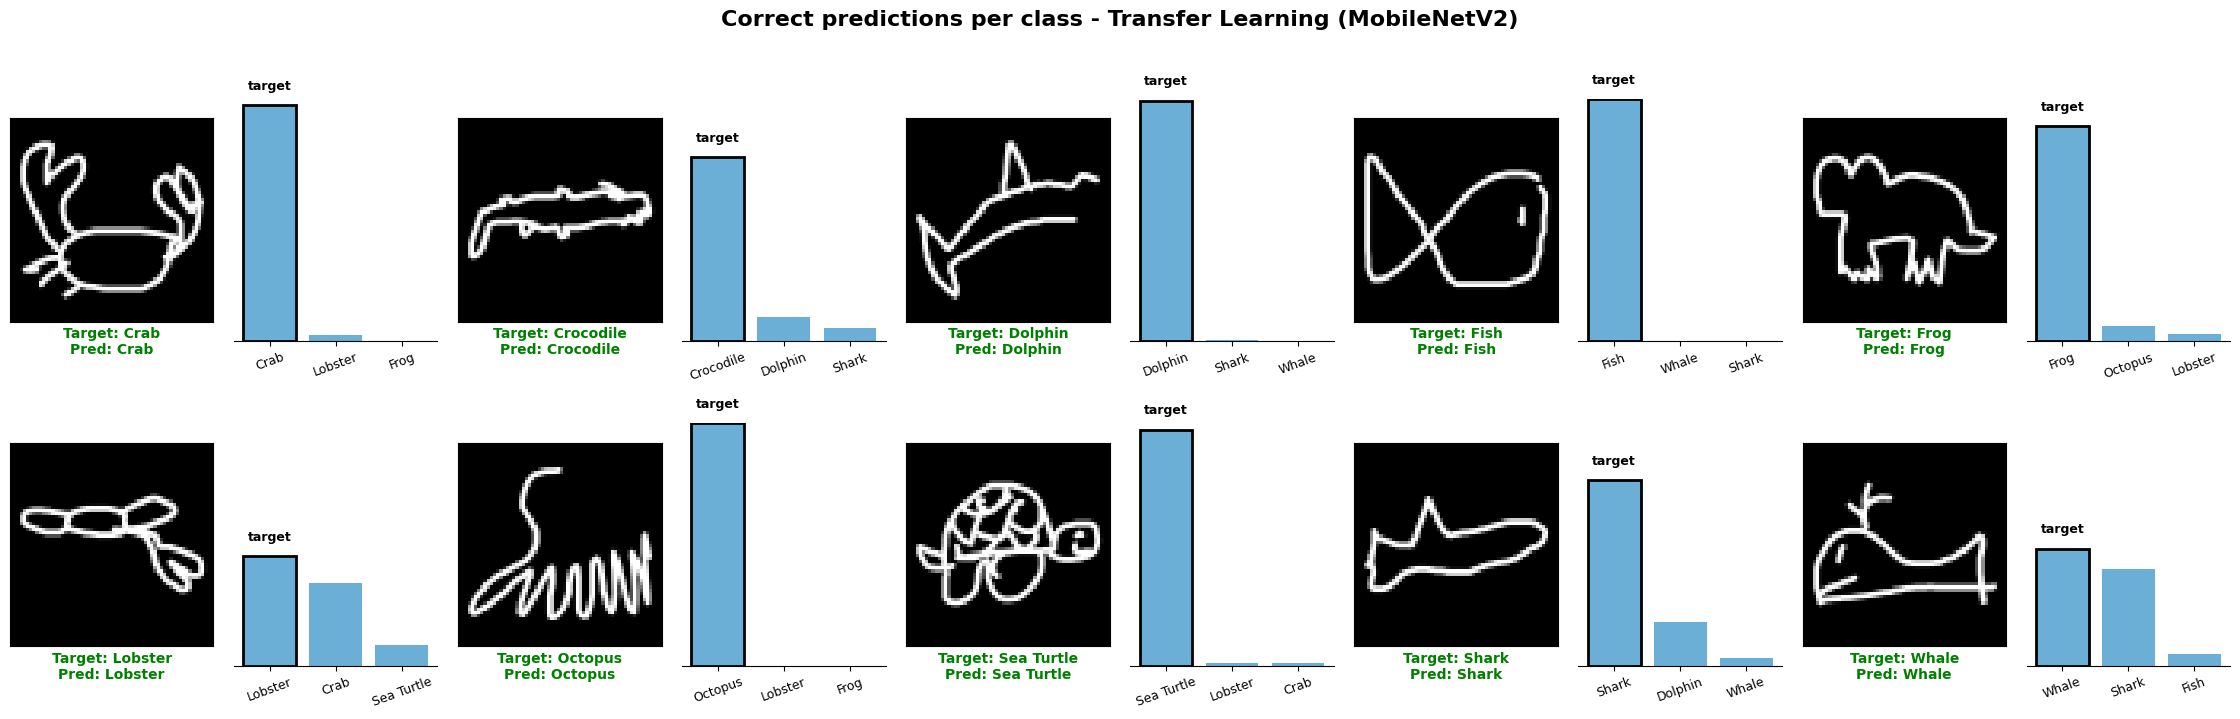

In [ ]:
# Display the prediction grid (correct images) of the Transfer Learning CNN
instantiated_models['Transfer'] = tf.keras.models.load_model(
    os.path.join(MODELS_DIR, 'TransferCNN.keras'))
x_val, y_val, preds_val = collect_arrays(
    instantiated_models['Transfer'], test_ds_rgb)
show_predictions_grid(x_val, y_val, preds_val, class_names,
                      model_label='Transfer Learning (MobileNetV2)',
                      mode='correct')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

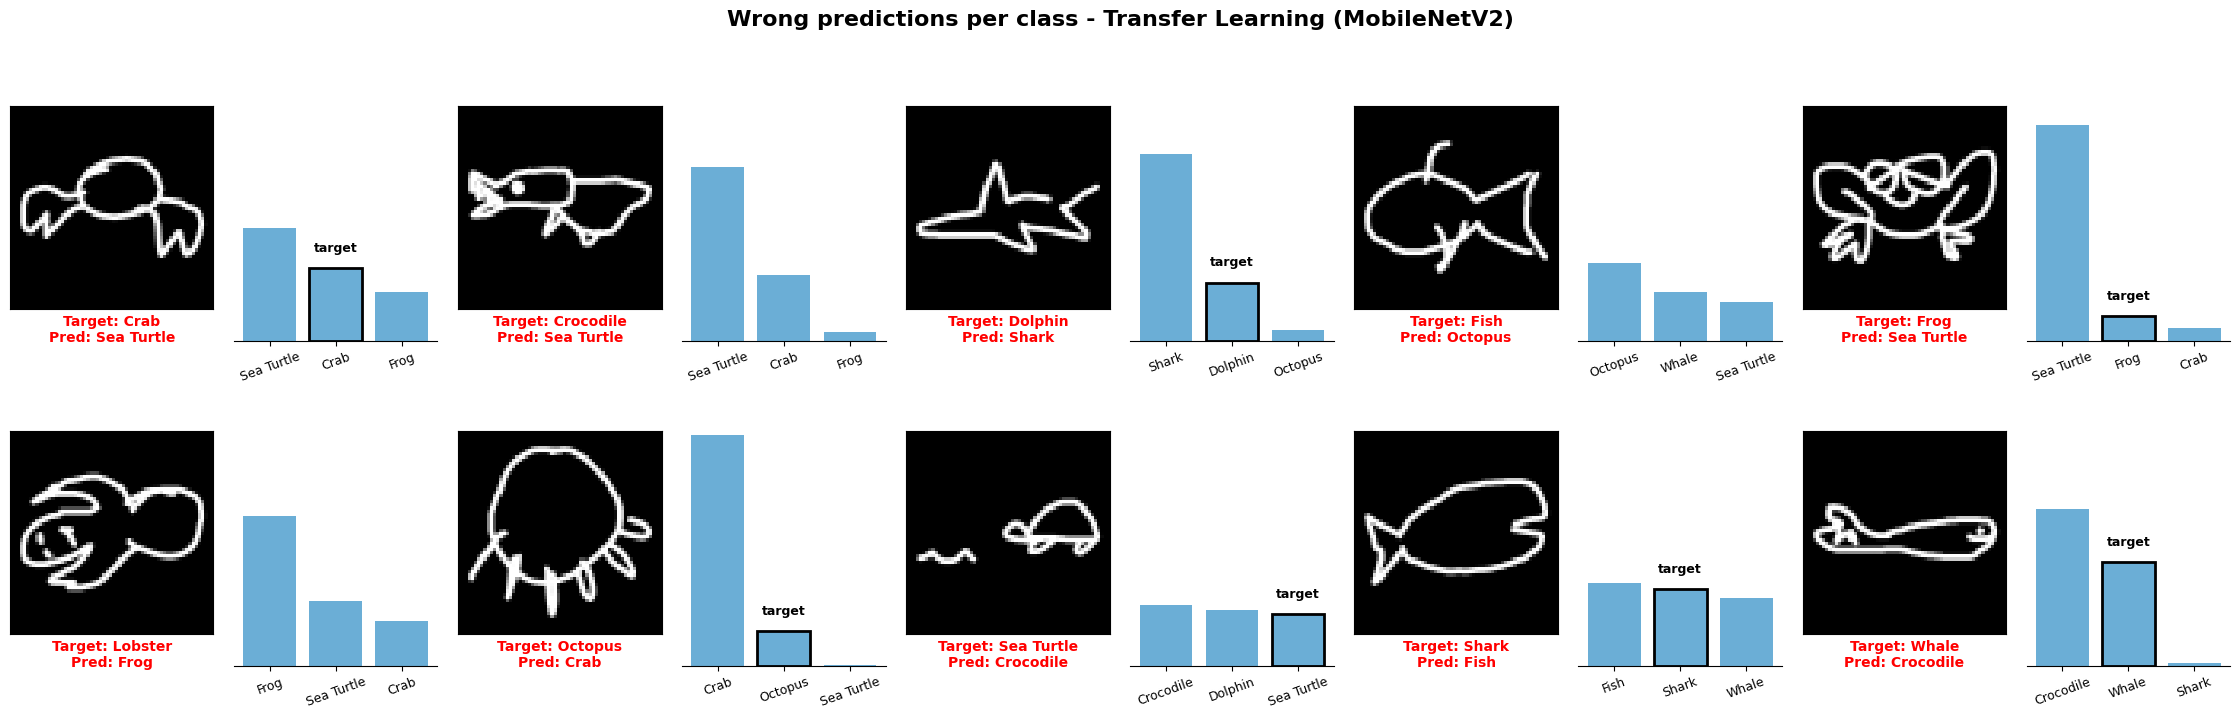

In [ ]:
# Display the prediction grid (wrong images) of the Transfer Learning CNN
show_predictions_grid(x_val, y_val, preds_val, class_names,
                      model_label='Transfer Learning (MobileNetV2)',
                      mode='wrong')

In this second stage, the model goes from frozen-backbone training to selective fine-tuning of MobileNetV2.
- Only the last 12 layers of the backbone are unfrozen, allowing the higher-level feature representations to adapt more closely to Quick, Draw! sketches while preserving the low-level filters learned from ImageNet.
- Training proceeds with a very low learning rate of 1e-5 to avoid disrupting the pretrained weights.

This stage is designed to assess whether slightly updating the upper convolutional blocks yields further improvements beyond the performance achieved with the frozen backbone.

In [ ]:
# Fine-tune the top layers of MobileNetV2
base_net = instantiated_models['Transfer'].get_layer('mobilenetv2_1.00_224')
base_net.trainable = True

# Print all layers to identify the start of the last block
for i, layer in enumerate(base_net.layers):
    print(i, layer.name)

# Find the index of the first layer of the last convolutional block
FINE_TUNE_AT = next(
    i for i, layer in enumerate(base_net.layers)
    if 'block_16' in layer.name)

for layer in base_net.layers[:FINE_TUNE_AT]:
    layer.trainable = False

print(f'\n-> Fine-tuning starts at layer {FINE_TUNE_AT}: '
      f'{base_net.layers[FINE_TUNE_AT].name}')
print(f'-> Fine-tuning the last {len(base_net.layers) - FINE_TUNE_AT} '
      f'layers of MobileNetV2 (out of {len(base_net.layers)})')

<IPython.core.display.Javascript object>

0 input_layer_1
1 Conv1
2 bn_Conv1
3 Conv1_relu
4 expanded_conv_depthwise
5 expanded_conv_depthwise_BN
6 expanded_conv_depthwise_relu
7 expanded_conv_project
8 expanded_conv_project_BN
9 block_1_expand
10 block_1_expand_BN
11 block_1_expand_relu
12 block_1_pad
13 block_1_depthwise
14 block_1_depthwise_BN
15 block_1_depthwise_relu
16 block_1_project
17 block_1_project_BN
18 block_2_expand
19 block_2_expand_BN
20 block_2_expand_relu
21 block_2_depthwise
22 block_2_depthwise_BN
23 block_2_depthwise_relu
24 block_2_project
25 block_2_project_BN
26 block_2_add
27 block_3_expand
28 block_3_expand_BN
29 block_3_expand_relu
30 block_3_pad
31 block_3_depthwise
32 block_3_depthwise_BN
33 block_3_depthwise_relu
34 block_3_project
35 block_3_project_BN
36 block_4_expand
37 block_4_expand_BN
38 block_4_expand_relu
39 block_4_depthwise
40 block_4_depthwise_BN
41 block_4_depthwise_relu
42 block_4_project
43 block_4_project_BN
44 block_4_add
45 block_5_expand
46 block_5_expand_BN
47 block_5_expand_rel

In [ ]:
# Train with lower learning rate, since large steps could destroy the pretrained representations
fine_tune_history = run_model_training(
    instantiated_models['Transfer'],
    train_ds_rgb, validation_ds_rgb,
    epochs=15, patience=5,
    save_name='TransferCNN_finetuned',
    learning_rate=1e-5)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Start Training: TransferCNN_finetuned
Epoch 1/15
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 82s 29ms/step - accuracy: 0.5600 - loss: 1.4475 - val_accuracy: 0.6738 - val_loss: 0.9654
Epoch 2/15
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 47s 21ms/step - accuracy: 0.6895 - loss: 0.9337 - val_accuracy: 0.7419 - val_loss: 0.7728
Epoch 3/15
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 44s 20ms/step - accuracy: 0.7360 - loss: 0.7855 - val_accuracy: 0.7668 - val_loss: 0.6914
Epoch 4/15
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.7619 - loss: 0.6987 - val_accuracy: 0.7846 - val_loss: 0.6344
Epoch 5/15
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 44s 20ms/step - accuracy: 0.7822 - loss: 0.6378 - val_accuracy: 0.7961 - val_loss: 0.5972
Epoch 6/15
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 42s 19ms/step - accuracy: 0.7974 - loss: 0.5920 - val_accuracy: 0.8045 - val_loss: 0.5732
Epoch 7/15
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.8084 - loss: 0.5574 - val_accuracy: 0.8137 - val_loss: 0.5512
Epoch 8/15
2188/2188 ━━━━━━━━━━━━━━━━

In [ ]:
# Merge the fine-tuning history with the head-training history so the
# learning curves show both stages continuously
histories['Transfer'] = np.load(
    os.path.join(MODELS_DIR, 'TransferCNN_history.npy'),
    allow_pickle=True).item()

for key in histories['Transfer']:
    histories['Transfer'][key] += fine_tune_history[key]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

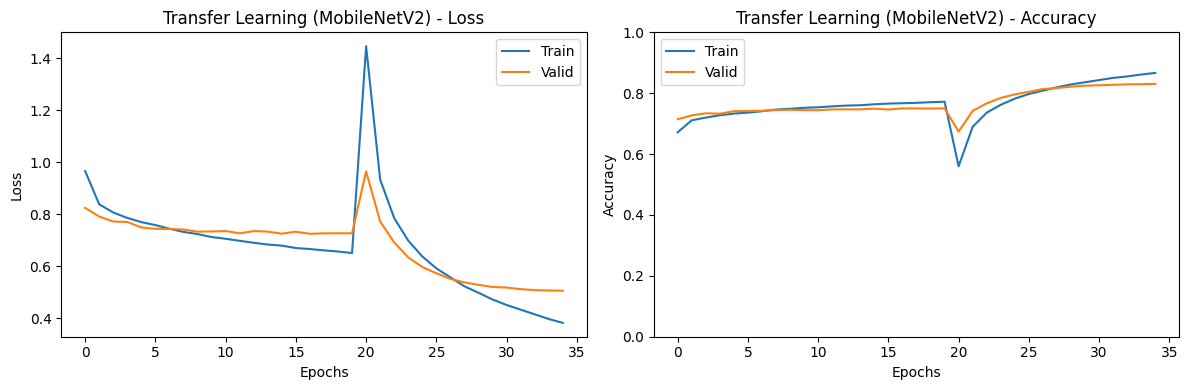

In [ ]:
# Display learning curves
plot_learning_curves(histories['Transfer'], 'Transfer Learning (MobileNetV2)')

In [ ]:
# Display test-set metrics
evaluate_on_testset(instantiated_models['Transfer'], test_ds_rgb, 'Transfer Learning (MobileNetV2)',
                    history_dict=histories['Transfer'])

<IPython.core.display.Javascript object>


Results on Test Set for Transfer Learning (MobileNetV2):
 -> Test Loss:     0.5008
 -> Test Accuracy: 0.8341
 -> Best Val Loss: 0.5059
 -> Best Val Acc:  0.8306



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

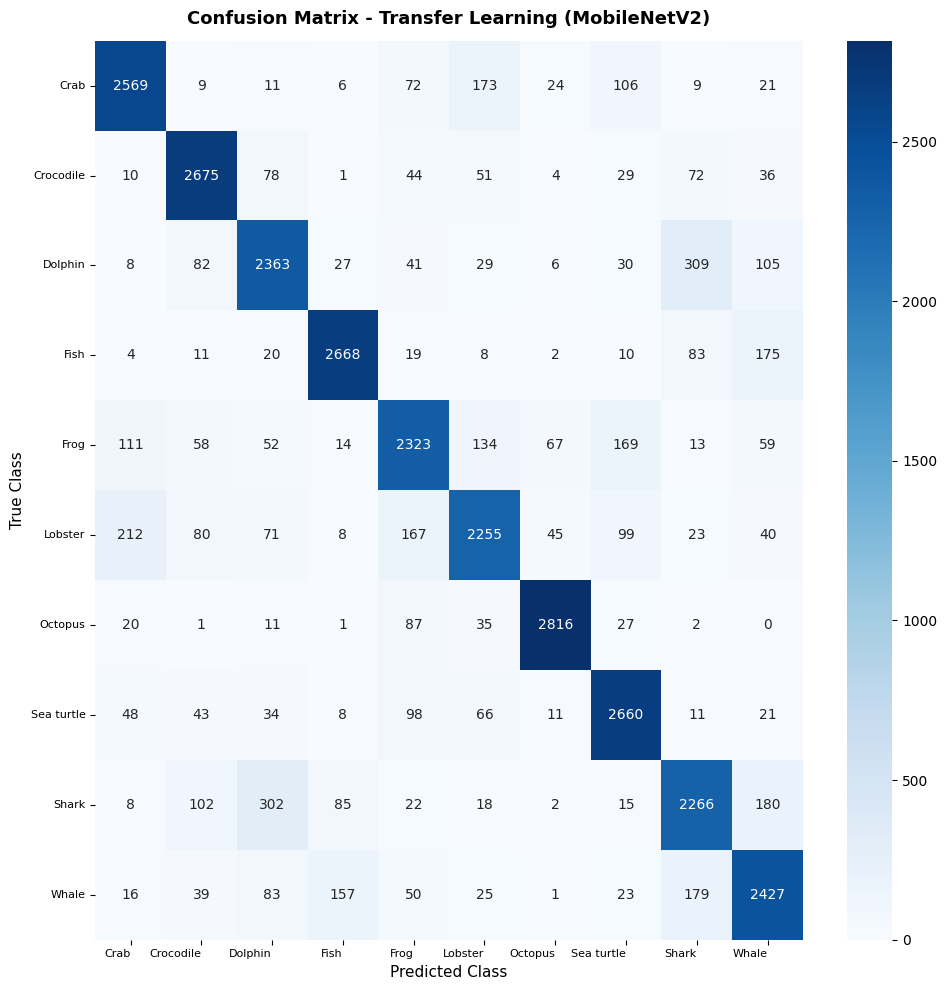

In [ ]:
# Display the confusion matrix
y_true, y_pred = plot_confusion_matrix(
    instantiated_models['Transfer'], test_ds_rgb, class_names, 'Transfer Learning (MobileNetV2)')

In [ ]:
# Display the classification report
plot_classification_report(y_true, y_pred, class_names, 'Transfer Learning (MobileNetV2)')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Classification Report - Transfer Learning (MobileNetV2):
              precision    recall  f1-score   support

        Crab       0.85      0.86      0.86      3000
   Crocodile       0.86      0.89      0.88      3000
     Dolphin       0.78      0.79      0.78      3000
        Fish       0.90      0.89      0.89      3000
        Frog       0.79      0.77      0.78      3000
     Lobster       0.81      0.75      0.78      3000
     Octopus       0.95      0.94      0.94      3000
  Sea turtle       0.84      0.89      0.86      3000
       Shark       0.76      0.76      0.76      3000
       Whale       0.79      0.81      0.80      3000

    accuracy                           0.83     30000
   macro avg       0.83      0.83      0.83     30000
weighted avg       0.83      0.83      0.83     30000



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

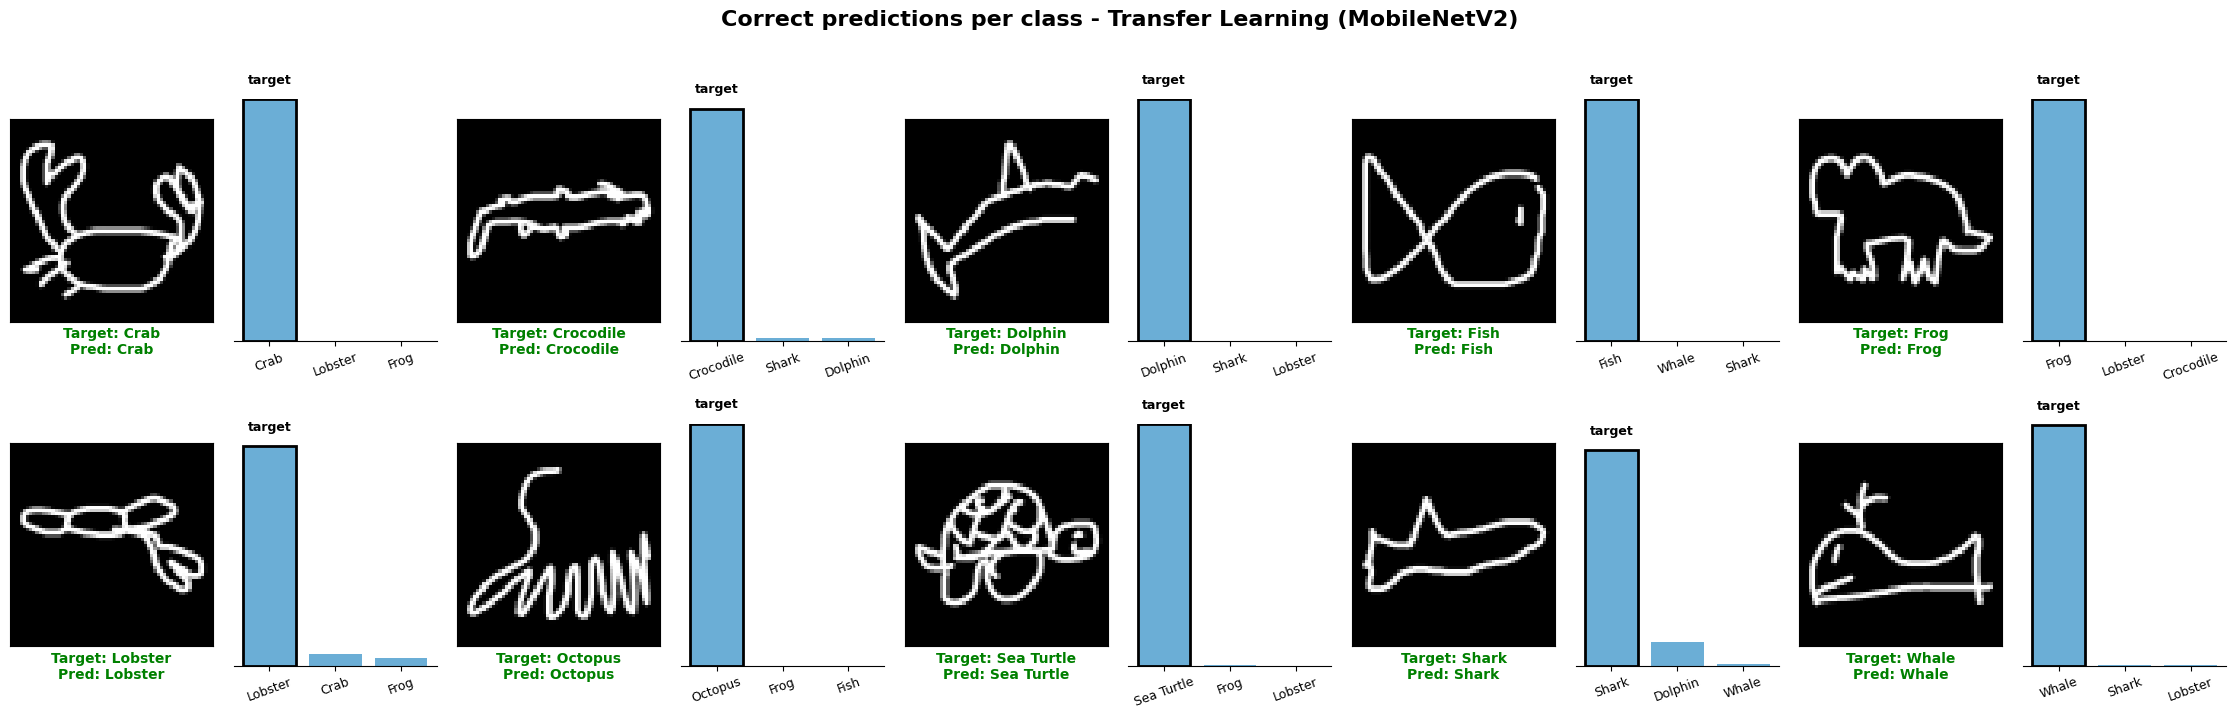

In [ ]:
# Display the prediction grid (correct images) of the fine-tuned TL CNN
x_val, y_val, preds_val = collect_arrays(
    instantiated_models['Transfer'], test_ds_rgb)
show_predictions_grid(x_val, y_val, preds_val, class_names,
                      model_label='Transfer Learning (MobileNetV2)',
                      mode='correct')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

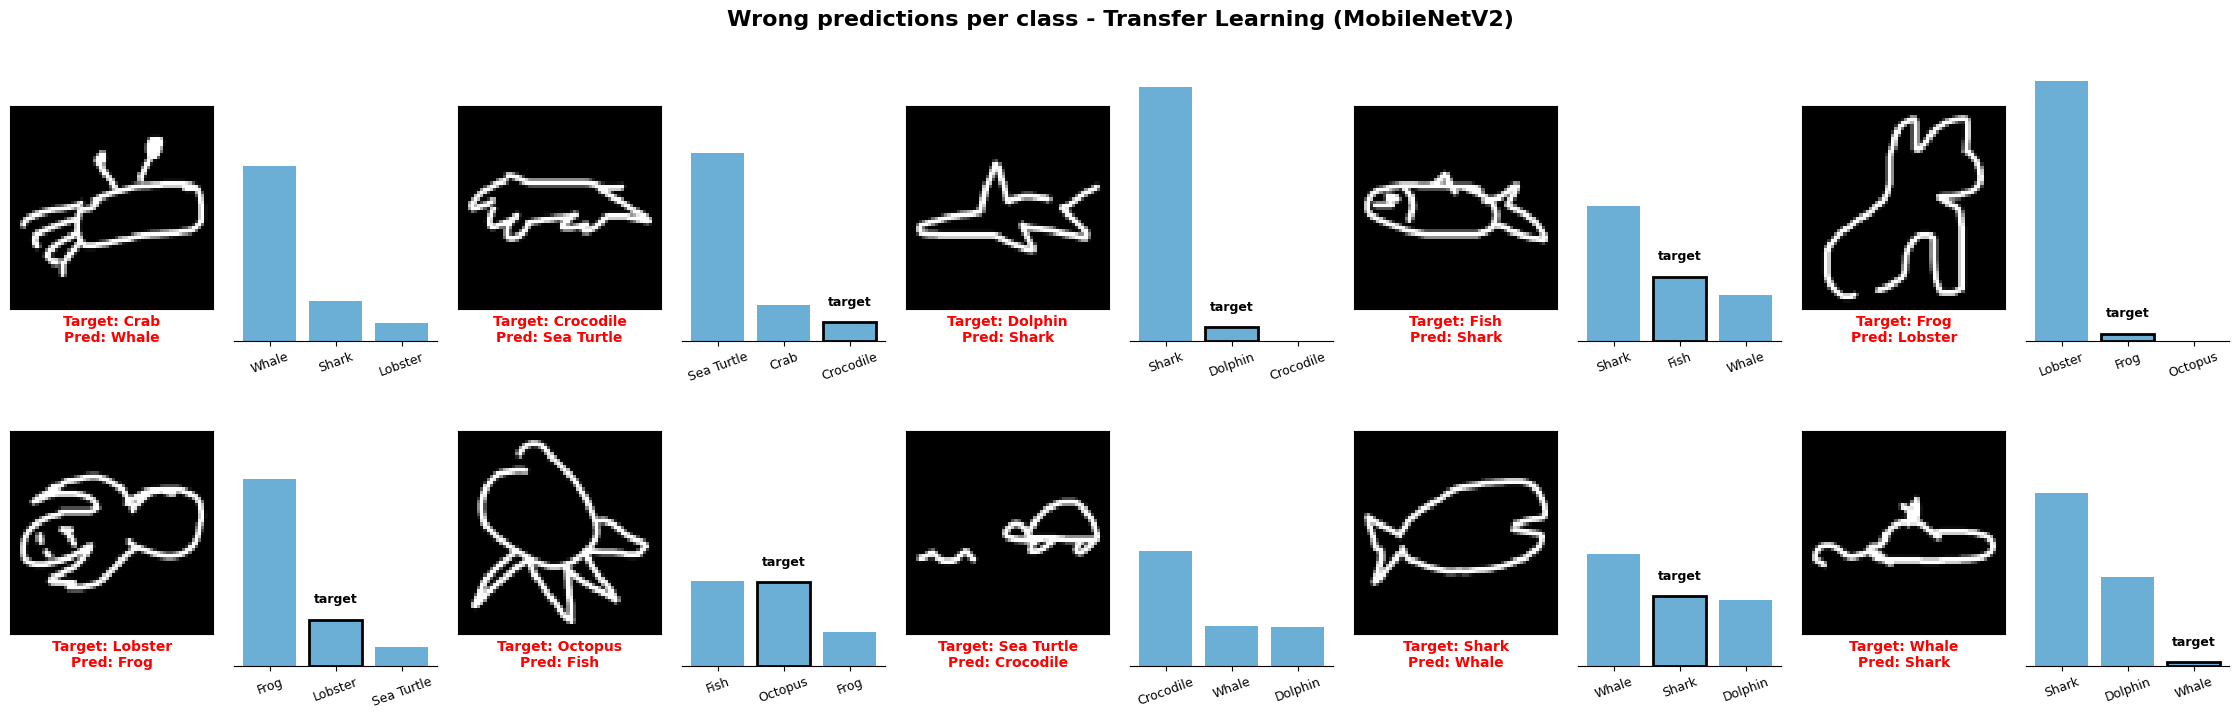

In [ ]:
# Display the prediction grid (wrong images) of the fine-tuned TL CNN
show_predictions_grid(x_val, y_val, preds_val, class_names,
                      model_label='Transfer Learning (MobileNetV2)',
                      mode='wrong')

---

#### **4.4.6 Model Comparison**

In [ ]:
def plot_model_comparison(models, accuracies, colors):
    '''Compare the accuracy of different models'''

    fig, ax = plt.subplots(figsize=(9, 5))

    bars = ax.bar(models, accuracies, color=colors, width=0.55, zorder=3)

    # Value labels on top of each bar
    for bar, acc in zip(bars, accuracies):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
                f'{acc:.1f}%', ha='center', va='bottom',
                fontsize=11, fontweight='bold')

    ax.set_ylim(60, 100)
    ax.set_ylabel('Test Accuracy (%)', fontsize=12)
    ax.set_title('Test Accuracy by Model',
                 fontsize=14, fontweight='bold', pad=15)
    ax.yaxis.grid(True, color='#E2E8F0', zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.savefig(os.path.join(VISUALIZATIONS_DIR, 'model_comparison.png'),
                dpi=300, bbox_inches='tight')
    plt.show()

<IPython.core.display.Javascript object>

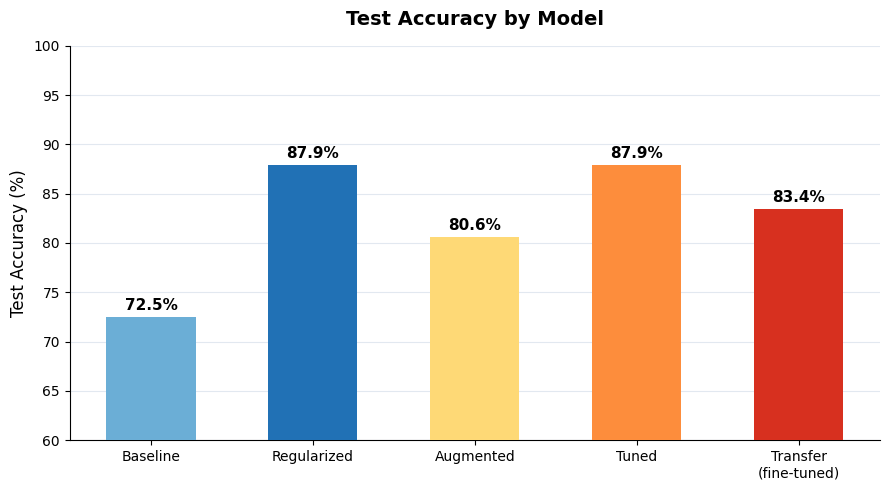

In [ ]:
# Display model comparison plot
models = ['Baseline', 'Regularized', 'Augmented',
          'Tuned', 'Transfer\n(fine-tuned)']
accuracies = [72.48, 87.90, 80.59, 87.89, 83.41]
colors = ['#6BAED6', '#2171B5', '#FED976', '#FD8D3C', '#D7301F']

plot_model_comparison(models, accuracies, colors)

---

## **5. Explainability**

In [ ]:
def load_model(model_path):
    '''Load a pretrained model'''
    model = tf.keras.models.load_model(model_path)
    return model


def get_all_conv_layer_names(model):
    '''Get the names of all convolutional layers in the model'''
    layer_names = []
    for layer in model.layers:
        if isinstance(layer, tf.keras.layers.Conv2D):
            layer_names.append(layer.name)

    if not layer_names:
        raise ValueError('No convolutional layer found in the model')
    return layer_names


def get_last_conv_layer_name(model):
    '''Get the name of the last convolutional layer in the model'''
    conv_layers = get_all_conv_layer_names(model)
    if conv_layers:
        return conv_layers[-1]
    raise ValueError('No convolutional layer found in the model')

<IPython.core.display.Javascript object>

In [ ]:
def make_gradcam_heatmap(
    image_array, model, conv_layer_name, pred_index=None):
    '''Compute the Grad-CAM heatmap associated with an image'''

    # Create a model that maps the input to both the activations
    # of the last convolution layer and the final model predictions
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(conv_layer_name).output, model.output])

    # Compute the gradient of the selected class
    with tf.GradientTape() as tape:
        image_tensor = tf.convert_to_tensor(image_array)
        conv_layer_output, preds = grad_model(image_tensor, training=False)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Compute the gradients of the target class score with respect to the
    # output feature maps of the last convolution layer
    grads = tape.gradient(class_channel, conv_layer_output)

    # Perform Global Average Pooling on the gradients
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Weigh the feature map channels
    conv_layer_output = conv_layer_output[0]
    heatmap = conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Apply ReLU and normalization to the heatmap
    heatmap = tf.maximum(heatmap, 0)
    max_val = tf.reduce_max(heatmap)
    heatmap = heatmap / (max_val + tf.keras.backend.epsilon())
    return heatmap.numpy()


def find_correct_images_batch(paths, model, true_index, batch_size=32):
    '''Found a correctly classified image by processing the dataset through
    a batch of size 32'''
    np.random.shuffle(paths)

    for i in range(0, len(paths), batch_size):
        batch_paths = paths[i : i + batch_size]

        # Load and preprocess all images of the batch
        batch_images = []
        for path in batch_paths:
            image = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
            image = cv2.resize(image, (64, 64))
            batch_images.append(image)

        batch_array = np.array(batch_images).astype(np.float32)
        batch_array = np.expand_dims(batch_array, axis=-1)

        # Compute the prediction for the entire batch
        preds = model.predict(batch_array, verbose=0)
        pred_classes = np.argmax(preds, axis=1)

        # Save a correctly classified image
        for index, pred_class in enumerate(pred_classes):
            if pred_class == true_index:
                return (
                    batch_paths[index],
                    batch_array[index:index+1],
                    batch_images[index])

    return None, None, None


def show_random_gradcam(
    dataset_directory, model, model_name, class_labels,
    split='test', image_size=(64, 64)):
    '''Display a Grad-CAM for one correctly classified image per class'''

    # Extract the name of all convolutional layers
    last_conv_layer = get_last_conv_layer_name(model)

    # Find one correctly classified image per class
    images_paths_per_class = get_image_paths(dataset_directory, split)
    selected = {}
    for true_class, paths in images_paths_per_class.items():
        if true_class not in class_labels:
            continue

        true_index = class_labels.index(true_class)
        path, image_array, image = find_correct_images_batch(
            paths, model, true_index)

        if path is not None:
            selected[true_class] = (path, image_array, image)
        else:
            print(f'-> No images found for class: {true_class}')

    # Display a grid of images
    n_classes = len(class_labels)
    fig, axes = plt.subplots(n_classes, 3, figsize=(6, n_classes * 3))

    for i, class_name in enumerate(class_labels):
        if class_name not in selected:
            print(f'-> No correct prediction found for class: {class_name}')
            for col in range(3):
                axes[i, col].axis('off')
            continue

        image_path, image_array, image = selected[class_name]

        # Compute the prediction
        preds = model.predict(image_array, verbose=0)
        pred_class_index = np.argmax(preds[0])
        predicted = class_labels[pred_class_index]

        # Display the Grad-CAM for the last convolutional layer
        heatmap = make_gradcam_heatmap(image_array, model, last_conv_layer)
        heatmap = np.uint8(255 * heatmap)
        jet = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
        jet = cv2.resize(jet, (image.shape[1], image.shape[0]),
                         interpolation=cv2.INTER_CUBIC)

        # Superimpose the heatmap on the original image
        jet_heatmap = np.uint8(
            0.5 * cv2.cvtColor(image, cv2.COLOR_GRAY2RGB) + 0.5 * jet)

        axes[i, 0].imshow(image, cmap='gray')
        axes[i, 0].set_title(f'Target: {class_name}')
        axes[i, 0].axis('off')

        axes[i, 1].imshow(heatmap, cmap='jet')
        axes[i, 1].set_title(f'Heatmap')
        axes[i, 1].axis('off')

        axes[i, 2].imshow(cv2.cvtColor(jet_heatmap, cv2.COLOR_BGR2RGB))
        axes[i, 2].set_title(f'Grad-CAM')
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(VISUALIZATIONS_DIR, f'gradcam_{model_name}.png'))
    plt.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

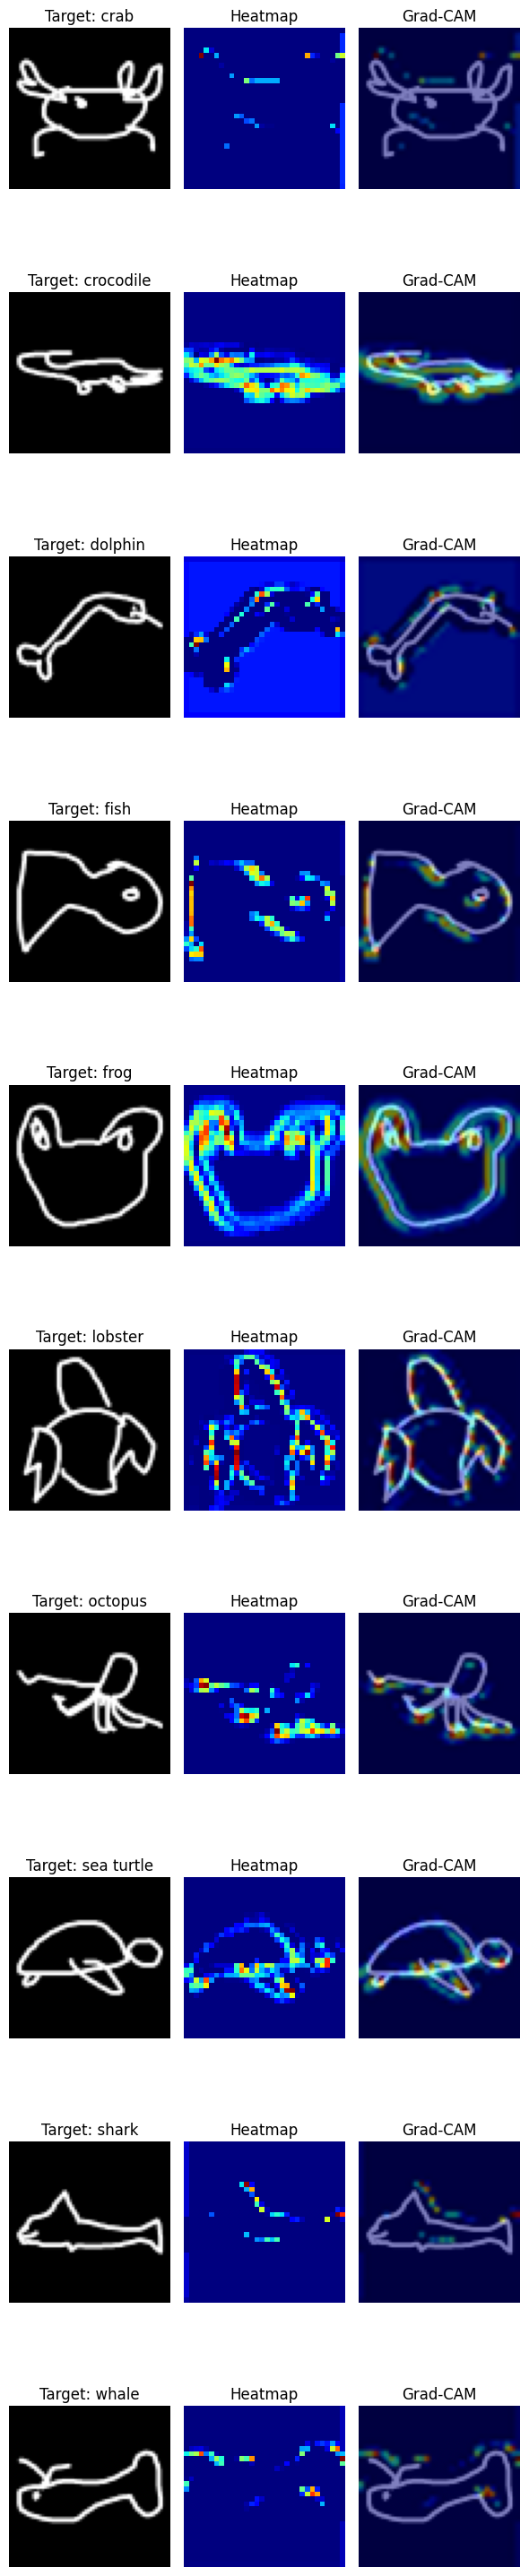

In [ ]:
# Load the baseline CNN and show a Grad-CAM for an image of each class
model = load_model(os.path.join(MODELS_DIR, 'BaselineCNN.keras'))
show_random_gradcam('/content/dataset', model, model_name='BaselineCNN',
                    class_labels=class_names, split='test')

<IPython.core.display.Javascript object>

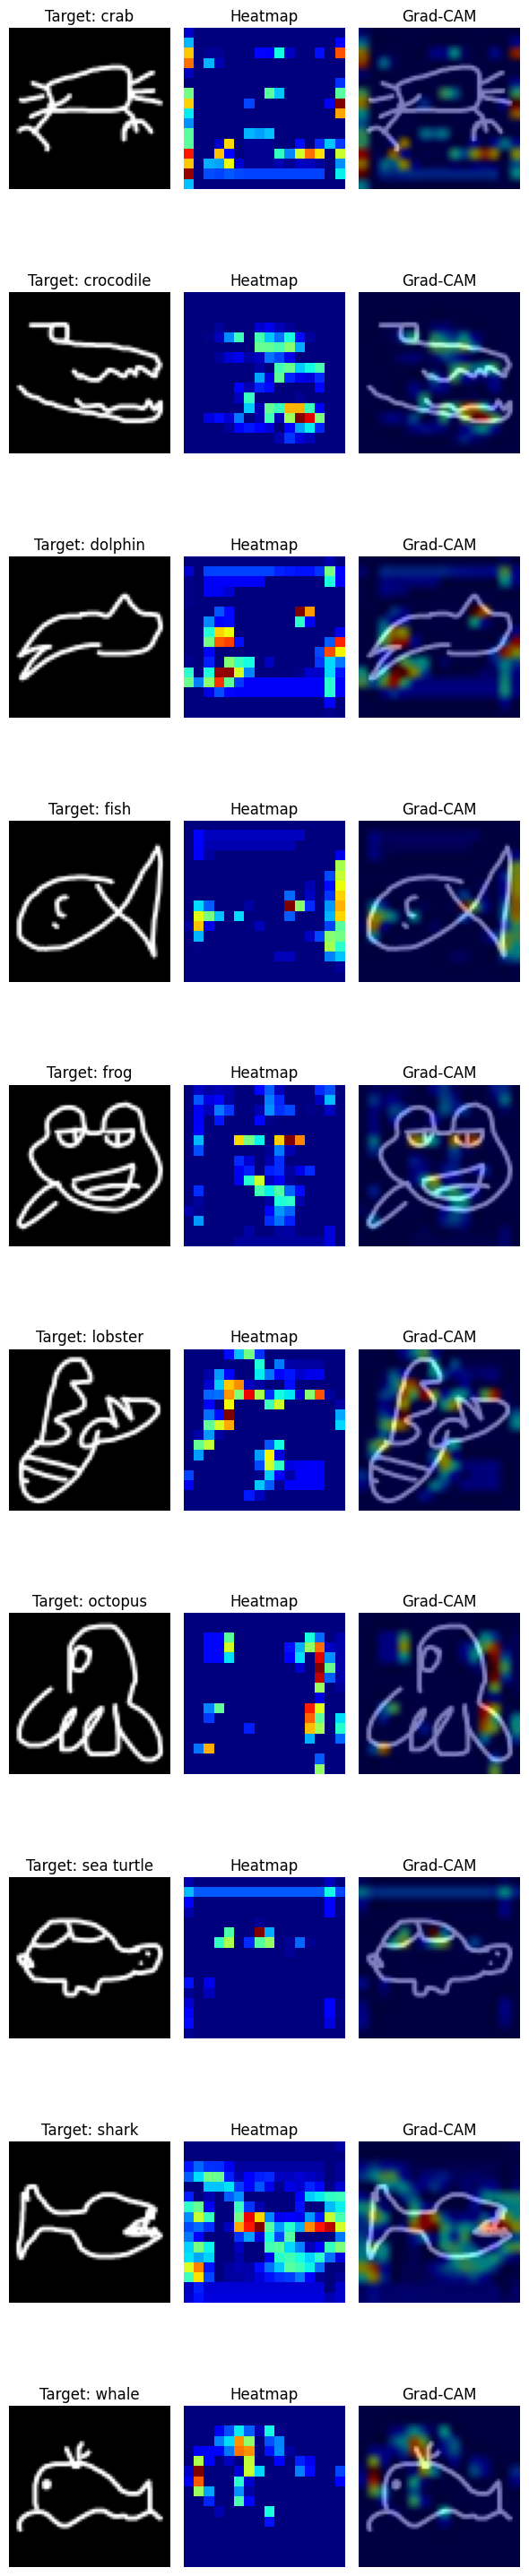

In [ ]:
# Load the regularized CNN and show a random Grad-CAM for each convolutional layer
model = load_model(os.path.join(MODELS_DIR, 'RegularizedCNN.keras'))
show_random_gradcam('/content/dataset', model, model_name='RegularizedCNN',
                    class_labels=class_names, split='test')

<IPython.core.display.Javascript object>

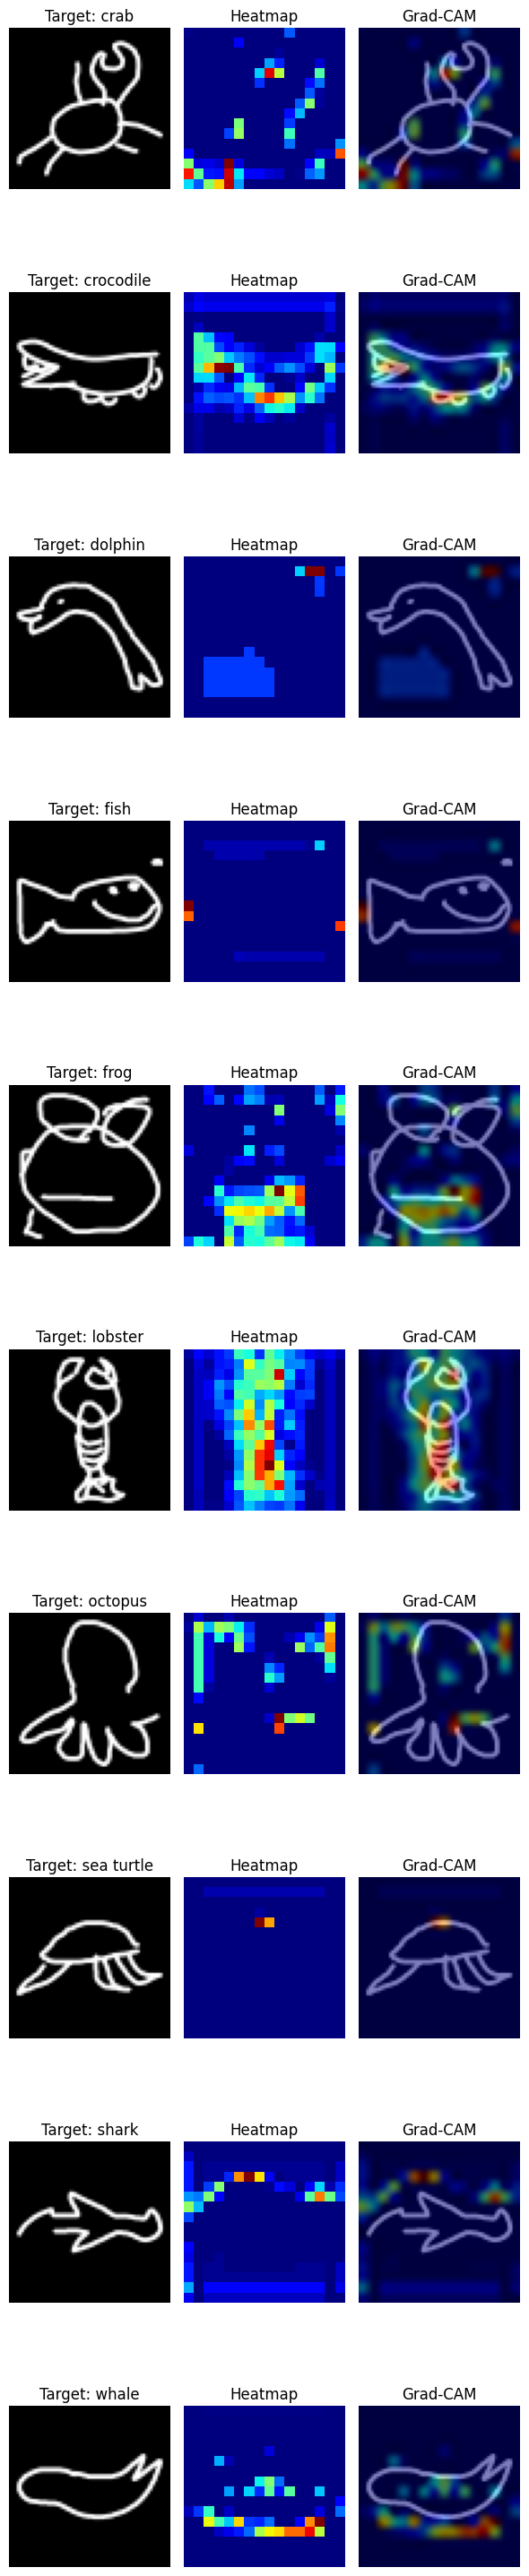

In [ ]:
# Load the augmented CNN and show a random Grad-CAM for each convolutional layer
model = load_model(os.path.join(MODELS_DIR, 'AugmentedCNN.keras'))
show_random_gradcam('/content/dataset', model, model_name='AugmentedCNN',
                    class_labels=class_names, split='test')

<IPython.core.display.Javascript object>

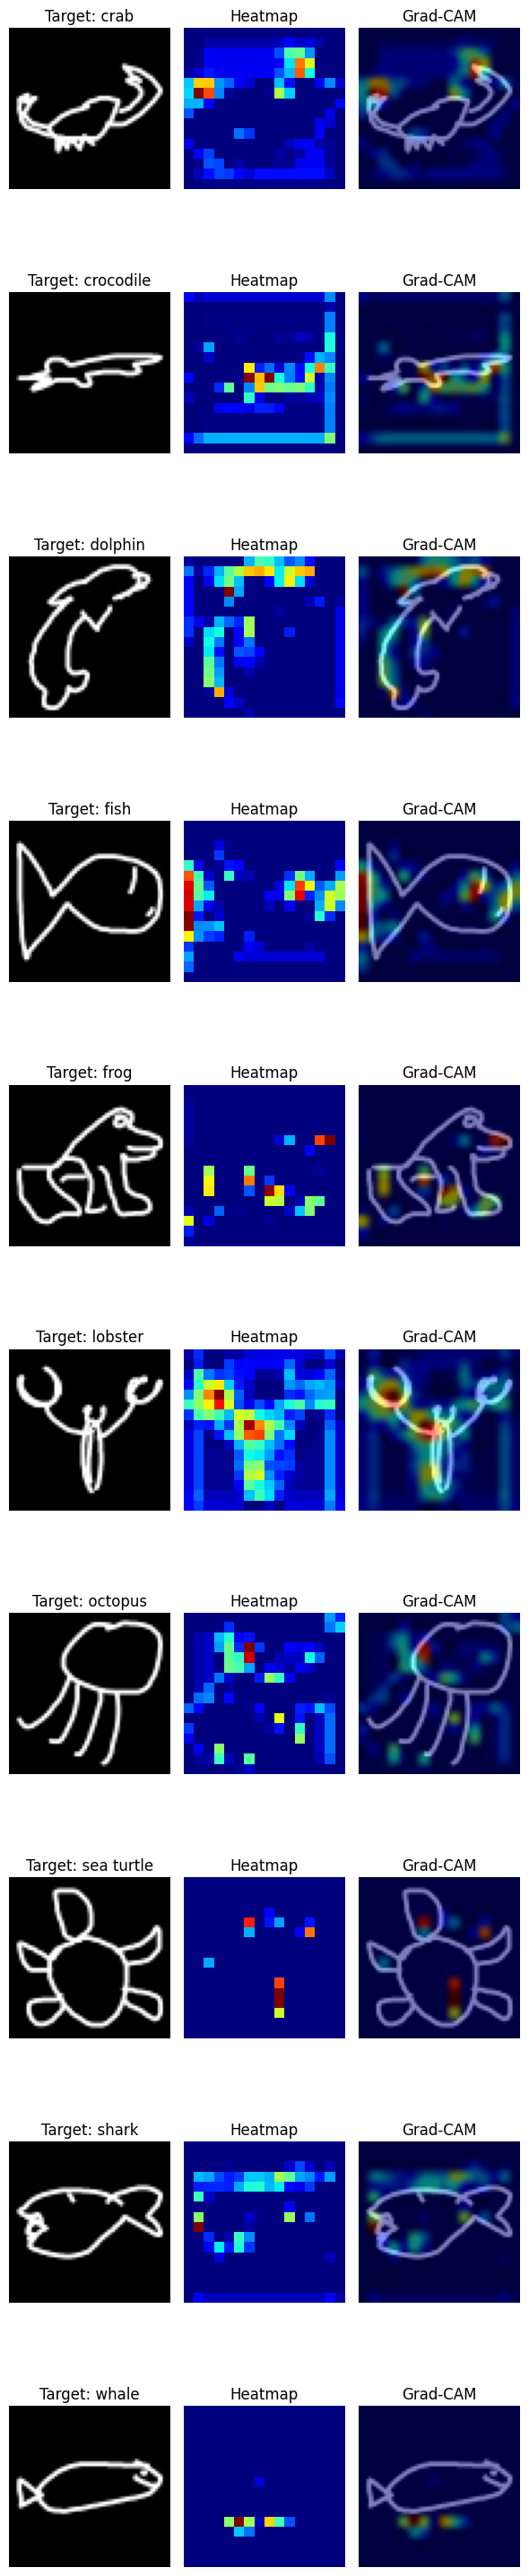

In [ ]:
# Load the tuned CNN and show a random Grad-CAM for each convolutional layer
model = load_model(os.path.join(MODELS_DIR, 'TunedCNN.keras'))
show_random_gradcam('/content/dataset', model, model_name='TunedCNN',
                    class_labels=class_names, split='test')